# 27 LSTM-Fingerabdruck: Normalbetrieb lernen, Stationen beschreiben

Teil 6: Lernende Modelle

**Worum es geht**

Die Kennzahlen aus Notebook 25 sind von Hand gebaut, und bei der Dämmung trennt die beste einzelne Kennzahl nur schwach (AUC 0,64). Ein LSTM, ein neuronales Netz für Zeitreihen mit Gedächtnis, soll deshalb aus den Stundenwerten selbst lernen, was eine Station ausmacht, ganz ohne Labels.

Das Netz liest einen Tag mit 24 Stunden und sechs Größen und sagt den nächsten Tag vorher. Dazwischen muss es den Tag in acht Zahlen pressen, das Embedding. Gemittelt über einen Winter und einen Sommer ergeben sich 16 Zahlen je Station, ihr Fingerabdruck. Fingerabdruck und Embedding meinen also dasselbe. Erst auf diesen Zahlen lernt eine logistische Regression, welche Stationen bei der Begehung einen Befund hatten.

Die Abschnitte 2 bis 5 zeigen in Vorversuchen, wie es zu diesem Aufbau kam: Tage als Sequenz, einfache Messlatten, ein erstes LSTM mit Lernkurve und Early Stopping, ein Engpass von 8 Zahlen und die Frage, ob dieser Steckbrief eine Station wiedererkennt. Die Abschnitte 6 bis 11 bauen das endgültige Netz. Nach Vorgabe der Betreuung lernt es nur auf Hausanschlussstationen mit Begehung und nur aus Tagen vor der Begehung. Alle anderen Zähler werden mit dem fertigen Netz nur übersetzt.

**Daten**
- liest: `modell_stunden.parquet`, `modell_labels.csv` und `modell_kennzahlen.csv` aus Notebook 25, für die Vorversuche die Zählerreihen aus Notebook 00
- schreibt: `lstm_embedding.csv` und `lstm_scores.csv` nach `data/processed/`, mit `SELBST_TRAINIEREN = True` auch die Gewichte nach `notebooks/models/` (Vorversuche in `vorversuche/`), Abbildungen nach `docs/assets/modelle/`
- vorher ausführen: Notebook 00 und 25

**Code**
- Netz, Training und Prüfung stehen im Notebook. Dieselbe Netzdefinition liegt für den Betrieb in `src/fehlerklassen.py` (`embedding_netz`).

## 1 Ausgangslage und Setup

### 1.1 Warum ein LSTM

Vor diesem Notebook hat das Projekt einiges versucht, um Fehler ohne passende Labels zu finden, etwa Anomalie-Scores und Regeln. Was davon trug und was nicht, steht in der Doku unter *Was nicht getragen hat*. Zwei Lehren bestimmen den Aufbau hier. Die Suche nach Ungewöhnlichem findet große Abnehmer und Messfehler, aber nicht die Fehler. Und ein großes Netz direkt auf die Labels zu trainieren, kommt nicht in Frage, denn bei 11 Ventilfällen und über 100.000 Gewichten würde es die Fälle auswendig lernen. Deshalb gibt es zwei Stufen: Das LSTM lernt ohne Labels aus zehntausenden Tagen, und erst danach nutzt eine einfache logistische Regression die 53 Labels.

### 1.2 Setup

Die Zelle lädt PyTorch für das Netz und scikit-learn für die Prüfung.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, LeaveOneOut, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROCESSED = ROOT / "data" / "processed"
MODELLE = ROOT / "notebooks" / "models"
MODELLE.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"

STICHTAG = pd.Timestamp("2024-09-01")
SELBST_TRAINIEREN = False   #True: alle Netze neu lernen, sonst die Gewichte aus notebooks/models/ laden
SEED = 0
torch.manual_seed(SEED)
GERAET = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__}, gerechnet auf: {GERAET}")

PyTorch 2.11.0+cu128, gerechnet auf: cuda


Mit `SELBST_TRAINIEREN = False` lernt das Notebook nichts neu. Es lädt alle Netze aus `notebooks/models/`, auch die der Vorversuche. Die Gewichte liegen nicht im Git, weil sie aus den Zählerdaten gelernt sind, und werden vom Projektteam weitergegeben. Fehlt eine Datei, hält das Notebook mit einem Hinweis an. Mit `True` lernt es alle Netze selbst und speichert sie dort. Mit Grafikkarte dauert das einige Minuten, auf der CPU mehrere Stunden. Weil alle Startwerte fest sind, kommen auf demselben Rechner dieselben Zahlen heraus.

Für die Vorversuche kommen der Ordner der Zählerreihen, ein Ordner für Abbildungen und einer für die Gewichte der Vorversuche dazu. `cudnn.deterministic` sorgt dafür, dass die Vorversuche auf der Grafikkarte bei jedem Lauf dieselben Zahlen liefern.

In [2]:
import copy
import sys

from scipy.spatial.distance import cdist

sys.path.insert(0, str(ROOT))
from src.weather import load_outdoor_temperature

METER_DIR = PROCESSED / "real_meters"
BILDER = ROOT / "docs" / "assets" / "modelle"
BILDER.mkdir(parents=True, exist_ok=True)
VORVERSUCHE = MODELLE / "vorversuche"
VORVERSUCHE.mkdir(parents=True, exist_ok=True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
geraet = GERAET

def gewichte_laden(datei):
    #nur mit SELBST_TRAINIEREN = False: gespeicherte Gewichte lesen statt lernen
    if not datei.exists():
        raise FileNotFoundError(f"{datei.relative_to(ROOT)} fehlt. Die Gewichte nach notebooks/models/ kopieren "
                                "oder oben SELBST_TRAINIEREN = True setzen.")
    return torch.load(datei, map_location=GERAET)

## 2 Vom Tag zur Sequenz

Bisher hatte jede Station ein paar Kennzahlen. Ein Median macht aber einen ganzen Winter zu einer Zahl, und wann am Tag etwas passiert, geht verloren. Jetzt bekommt jeder Tag eine Zeile mit 24 Stunden, zuerst für den Ventilfall 68956351 aus Notebook 25:

In [3]:
df = pd.read_csv(METER_DIR / "68956351.csv", parse_dates=["Timestamp"])
df["tag"] = df["Timestamp"].dt.date
df["stunde"] = df["Timestamp"].dt.hour

In [4]:
tage_rl = df.pivot(index="tag", columns="stunde", values="Return temperature (°C)")
tage_rl.head()

stunde,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
tag,,,,,,,,,,,,,,,,,,,,,,,,
2021-11-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75.5
2021-11-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75.1
2021-11-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75.7
2021-11-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,68.2
2021-11-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,73.0


In [5]:
tage_rl.shape

(1349, 24)

Das sind 1349 Kalendertage. Ein Netz braucht vollständige Tage, also fallen alle Tage weg, an denen auch nur eine Stunde fehlt:

In [6]:
volle_tage = tage_rl.dropna()

In [7]:
volle_tage.shape

(960, 24)

Es bleiben 960 vollständige Tage, also 71 %. Die übrigen fallen vor allem in die Zeit bis Oktober 2022, in der der Zähler nur einen Wert je Tag lieferte (Notebook 25, Abschnitt 6.1).

In [8]:
volle_tage.index = pd.to_datetime(volle_tage.index)

Vier Wintertage, zwei vor und zwei nach dem Tausch:

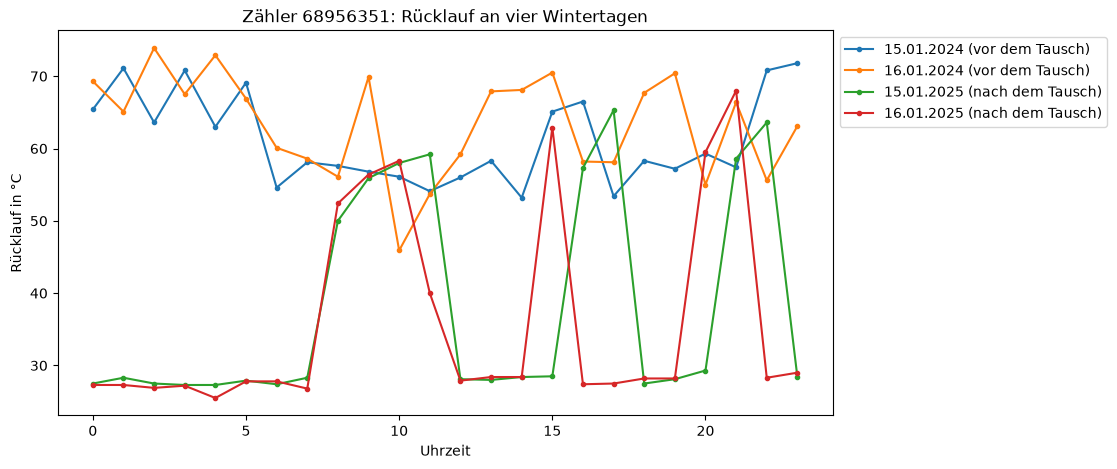

In [9]:
beispiel = volle_tage.loc[["2024-01-15", "2024-01-16", "2025-01-15", "2025-01-16"]]
ax = beispiel.T.plot(figsize=(10, 5), marker=".")
ax.set_title("Zähler 68956351: Rücklauf an vier Wintertagen")
ax.set_xlabel("Uhrzeit")
ax.set_ylabel("Rücklauf in °C")
ax.legend(["15.01.2024 (vor dem Tausch)", "16.01.2024 (vor dem Tausch)", "15.01.2025 (nach dem Tausch)", "16.01.2025 (nach dem Tausch)"],
          loc="upper left", bbox_to_anchor=(1, 1));

In [10]:
ax.figure.savefig(BILDER / "29_tage_vor_nach.png", bbox_inches="tight")

Vor dem Tausch bleibt der Rücklauf den ganzen Tag hoch, zwischen etwa 55 und 71 °C. Danach springt er zwischen etwa 28 und 60 °C. Das ruhige Bild vorher ist der Fehler, denn das Ventil schließt nie. Nachher öffnet die Station nur, wenn Wärme gebraucht wird, und dazwischen steht das Wasser und kühlt ab (Takten). Das sieht man nur im Tagesverlauf, nicht in einer Kennzahl wie dem Wintermittel. Ein Modell, das ganze Tage liest, kann solche Muster nutzen.

### 2.1 Mehrere Kanäle

Je Stunde soll das Modell mehrere Messgrößen sehen, Rücklauf, Durchfluss und Vorlauf. Jede Messgröße ist ein Kanal.

In [11]:
kanaele = {
    "ruecklauf": "Return temperature (°C)",
    "durchfluss": "Volume flow (l/h)",
    "vorlauf": "Flow temperature (°C)",
}

tabellen = {}
for name, spalte in kanaele.items():
    tabellen[name] = df.pivot(index="tag", columns="stunde", values=spalte)

In [12]:
alle = pd.concat(tabellen, axis=1).dropna()
alle.shape

(960, 72)

In [13]:
X = alle.values.reshape(len(alle), 3, 24).transpose(0, 2, 1)
X.shape

(960, 24, 3)

So entsteht ein Feld aus Tagen × 24 Stunden × 3 Kanälen, wie ein Buch: Jede Seite ist ein Tag, jede Zeile eine Stunde, jede Spalte ein Kanal.

### 2.2 Skalierung

Die Kanäle liegen in ganz verschiedenen Größenordnungen, der Durchfluss bei bis zu fast 1000 l/h, die Temperaturen zwischen 25 und 80 °C. Ohne Skalierung würde im Netz der Kanal mit den größten Zahlen alles bestimmen. Mittelwert und Streuung kommen nur aus der Zeit vor dem Tausch, sonst steckt Wissen aus der Zukunft in der Skalierung (Leakage).

In [14]:
vor_tausch = pd.to_datetime(alle.index) < "2024-09-09"
X_vor = X[vor_tausch]

In [15]:
mittel = X_vor.mean(axis=(0, 1))
streuung = X_vor.std(axis=(0, 1))
mittel, streuung

(array([ 74.32725431, 672.10758612,  76.57160588]),
 array([  5.64633127, 139.19167023,   3.20391482]))

In [16]:
X_skaliert = (X - mittel) / streuung

Vor dem Tausch hat jetzt jeder Kanal Mittelwert 0 und Streuung 1. Und nach dem Tausch?

In [17]:
X_skaliert[~vor_tausch].mean(axis=(0, 1))

array([-5.84986747, -4.30116717, -5.16596032])

Nach dem Tausch liegen alle drei Kanäle im Mittel 4 bis 6 Streuungen unter dem, was vorher normal war. Die Streuung ist dabei nicht größer geworden, die Werte haben sich verschoben, weil sich die Station ganz anders verhält als vorher. Genau so soll später ein Wächter Veränderungen finden (Notebook 28).

### 2.3 Alle begangenen Stationen

Dasselbe gilt jetzt für alle begangenen Stationen, jeweils ab November 2022, weil es vorher nur Tageswerte gab, und vor der Begehung, spätestens bis zum Stichtag. Als vierter Kanal kommt die Außentemperatur dazu, denn ohne Wetter lässt sich der nächste Tag nicht vorhersagen.

In [18]:
labels = pd.read_csv(ROOT / "data" / "processed" / "modell_labels.csv", parse_dates=["erste_begehung"])
labels["ende"] = labels["erste_begehung"].fillna(pd.Timestamp("2024-09-01")).clip(upper=pd.Timestamp("2024-09-01"))

In [19]:
from src.weather import load_outdoor_temperature

wetter = load_outdoor_temperature("2022-11-01", "2024-09-01")
wetter["tag"] = wetter["timestamp"].dt.date
wetter["stunde"] = wetter["timestamp"].dt.hour
aussen = wetter.pivot(index="tag", columns="stunde", values="t_out")

Für jede Station dasselbe wie oben. In `info_liste` steht, zu welcher Station und welchem Tag jede Zeile gehört, im Feld stehen ja nur Zahlen:

In [20]:
X_liste = []
info_liste = []

for z, ende in zip(labels["zaehler"], labels["ende"]):
    d = pd.read_csv(METER_DIR / f"{z}.csv", parse_dates=["Timestamp"])
    d = d[(d["Timestamp"] >= "2022-11-01") & (d["Timestamp"] < ende)]
    if len(d) == 0:
        continue
    d["tag"] = d["Timestamp"].dt.date
    d["stunde"] = d["Timestamp"].dt.hour

    tabellen = {}
    for name, spalte in kanaele.items():
        tabellen[name] = d.pivot(index="tag", columns="stunde", values=spalte)
    tabellen["aussen"] = aussen

    alle = pd.concat(tabellen, axis=1).dropna()
    X_liste.append(alle.values.reshape(len(alle), 4, 24).transpose(0, 2, 1))
    info_liste.append(pd.DataFrame({"zaehler": z, "tag": alle.index}))

In [21]:
import numpy as np

X_alle = np.concatenate(X_liste)
info = pd.concat(info_liste, ignore_index=True)
X_alle.shape

(24684, 24, 4)

In [22]:
info["zaehler"].nunique()

54

Das ergibt 24.684 Tage × 24 Stunden × 4 Kanäle von 54 Stationen. Bei 2 der 56 begangenen Zähler gibt es vor dem Stichtag keine Messwerte.

## 3 Messlatten für den nächsten Tag

Das LSTM soll später aus einem Tag den nächsten vorhersagen. Vorher braucht es Messlatten ohne Lernen, „wie gestern“ und das Mittel der letzten 7 Tage. Gemessen wird, wie viel Grad die Vorhersage beim Rücklauf im Mittel danebenliegt (mittlerer absoluter Fehler).

In [23]:
rl = pd.DataFrame(X_alle[:, :, 0])
rl["zaehler"] = info["zaehler"]
rl["tag"] = pd.to_datetime(info["tag"])

In [24]:
fehler_gestern = []
fehler_woche = []

for z, gruppe in rl.groupby("zaehler"):
    g = gruppe.set_index("tag").drop(columns="zaehler").asfreq("D")
    gestern = g.shift(1)
    woche = g.rolling(7).mean().shift(1)

    da = woche.notna().all(axis=1) & g.notna().all(axis=1)
    fehler_gestern.append((g - gestern)[da].abs())
    fehler_woche.append((g - woche)[da].abs())

`asfreq("D")` fügt fehlende Tage als leere Zeilen ein, sonst wäre „gestern“ einfach die vorherige Zeile. `shift(1)` sorgt dafür, dass der vorhergesagte Tag nicht selbst im Mittel steckt.

In [25]:
print("wie gestern:", pd.concat(fehler_gestern).values.mean())
print("Mittel 7 Tage:", pd.concat(fehler_woche).values.mean())

wie gestern: 5.72564842209073
Mittel 7 Tage: 5.226790238853849


„Wie gestern“ liegt im Mittel 5,7 K daneben, das Mittel der letzten 7 Tage 5,2 K, weil es den Zufall des Taktens wegglättet. Das 7-Tage-Mittel ist damit die Messlatte, die ein gelerntes Modell schlagen muss.

### 3.1 Aufteilung nach der Zeit

Ab jetzt wird gelernt, also braucht es Training, Validierung und Test. Zufällig nach Tagen aufteilen geht nicht, denn Nachbartage gleichen sich fast aufs Haar, und ein Testtag hätte seinen Vortag im Training. Trainiert wird deshalb auf November 2022 bis Mai 2024, davon gehen 10 % ganze Kalenderwochen in die Validierung. Getestet wird auf Juni bis August 2024, also vor allen Begehungen.

In [26]:
info["tag"] = pd.to_datetime(info["tag"])
info["woche"] = info["tag"].dt.to_period("W").astype(str)

In [27]:
test = info["tag"] >= "2024-06-01"

wochen = info.loc[~test, "woche"].unique()
np.random.seed(0)
val_wochen = np.random.choice(wochen, size=int(0.1 * len(wochen)), replace=False)

val = info["woche"].isin(val_wochen) & ~test
train = ~test & ~val

In [28]:
train.sum(), val.sum(), test.sum()

(np.int64(18689), np.int64(1511), np.int64(4484))

Das ergibt rund 76 % Training, 6 % Validierung und 18 % Test. Ganze Wochen statt einzelner Tage nimmt man, weil sich Nachbartage fast gleichen. Läge der 14. Januar in der Validierung und der 13. im Training, wäre die Prüfung zu leicht.

### 3.2 Ein erstes gelerntes Modell: Ridge-Regression

Ridge bekommt einen ganzen Tag (24 × 4 Werte) und die Außentemperatur von morgen und sagt den Rücklauf von morgen vorher. Die Außentemperatur von morgen gäbe es im Betrieb als Wettervorhersage. Dafür braucht es Paare aus heute und morgen derselben Station.

In [29]:
naechster = info.groupby("zaehler")["tag"].shift(-1)
paar = (naechster - info["tag"]) == pd.Timedelta(days=1)
heute = np.where(paar)[0]
morgen = heute + 1

In [30]:
eingabe = np.concatenate([X_alle[heute].reshape(len(heute), -1), X_alle[morgen, :, 3]], axis=1)
ziel = X_alle[morgen, :, 0]
eingabe.shape, ziel.shape

((24236, 120), (24236, 24))

120 Zahlen rein, 24 raus. Der `StandardScaler` steckt in der Pipeline und lernt deshalb nur aus dem Training:

In [31]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ist_train = train.values[morgen]
ist_val = val.values[morgen]
ist_test = test.values[morgen]

ridge = make_pipeline(StandardScaler(), Ridge(alpha=10))
ridge.fit(eingabe[ist_train], ziel[ist_train])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,120
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](120,)","[ 43.45,123.85, 61.9 ,..., 10.02, 9.23, 8.66]"


In [32]:
for name, teil in [("Validierung", ist_val), ("Test", ist_test)]:
    f_ridge = np.abs(ridge.predict(eingabe[teil]) - ziel[teil]).mean()
    f_gestern = np.abs(X_alle[heute][teil][:, :, 0] - ziel[teil]).mean()
    print(name, "Ridge:", round(f_ridge, 2), "  wie gestern:", round(f_gestern, 2))

Validierung Ridge: 5.31   wie gestern: 5.85
Test Ridge: 4.84   wie gestern: 4.71


Aus welchen Monaten kommen die Trainingstage?

In [33]:
monat = info["tag"].dt.month.values[morgen]
pd.Series(monat[ist_train]).value_counts().sort_index()

1     1834
2     2035
3     2261
4     2212
5     2167
6      688
7      695
8      450
9      830
10    1256
11    1631
12    2349
Name: count, dtype: int64

Auf der Validierung ist Ridge besser als „wie gestern“ (5,31 gegen 5,85 K), im Test, dem Sommer 2024, schlechter (4,84 gegen 4,71 K). Den Grund zeigt die Monatstabelle: Nur 1.833 Trainingstage stammen aus Juni bis August, aber 6.218 aus Dezember bis Februar. Ridge hat vor allem den Heizbetrieb gelernt, und der Test unterscheidet sich vom Training (Verteilungsverschiebung). Für das LSTM folgt daraus, dass der Sommer getrennt geprüft werden muss, zumal dort das Ventilsignal liegt.

## 4 Ein erstes LSTM

Ein LSTM liest einen Tag Stunde für Stunde und trägt dabei ein Gedächtnis mit, einen Satz Zahlen, der nach jeder Stunde neu geschrieben wird. Drei Tore entscheiden, was vergessen, was neu aufgenommen und was ausgegeben wird. Die Tore haben eine Sigmoid-Aktivierung mit Werten zwischen 0 und 1, wie ein Regler, die Inhalte eine tanh-Aktivierung mit Werten zwischen −1 und 1. Gerechnet wird auf der Grafikkarte, wenn es eine gibt.

In [34]:
ein_tag = torch.tensor(X_alle[:1], dtype=torch.float32)
ein_tag.shape

torch.Size([1, 24, 4])

PyTorch will immer einen Stapel, auch wenn er nur einen Tag enthält, also 1 Tag × 24 Stunden × 4 Kanäle. Hier ein noch untrainiertes LSTM mit 4 Eingängen und 8 Gedächtniszahlen:

In [35]:
lstm = torch.nn.LSTM(input_size=4, hidden_size=8, batch_first=True)
ausgabe, (h, c) = lstm(ein_tag)
ausgabe.shape

torch.Size([1, 24, 8])

Heraus kommen 1 Tag × 24 Stunden × 8 Gedächtniszahlen, also 8 Zahlen nach jeder Stunde. Die 8 ist die Größe des Gedächtnisses, nicht die Zahl der Tage. Was steckt im letzten Zustand `h`?

In [36]:
print(ausgabe[0, -1])
print(h[0, 0])

tensor([ 1.3114e-06,  6.8753e-02,  8.1030e-09,  2.2269e-08,  6.8768e-01,
        -3.4731e-01,  1.1568e-01, -2.0688e-10], grad_fn=<SelectBackward0>)
tensor([ 1.3114e-06,  6.8753e-02,  8.1030e-09,  2.2269e-08,  6.8768e-01,
        -3.4731e-01,  1.1568e-01, -2.0688e-10], grad_fn=<SelectBackward0>)


Es sind dieselben 8 Zahlen, denn `h` ist das Gedächtnis nach der letzten Stunde, also die Zusammenfassung des ganzen Tages. Für eine Vorhersage kommt hinter das LSTM eine lineare Schicht, die aus dem Gedächtnis 24 Zahlen macht, den Rücklauf von morgen. Sie hat keine Aktivierung, weil sie beliebige Werte ausgeben soll.

In [37]:
class Vorhersage(torch.nn.Module):
    def __init__(self, kanaele, gedaechtnis):
        super().__init__()
        self.lstm = torch.nn.LSTM(input_size=kanaele, hidden_size=gedaechtnis, batch_first=True)
        self.ausgang = torch.nn.Linear(gedaechtnis, 24)

    def forward(self, x):
        ausgabe, (h, c) = self.lstm(x)
        return self.ausgang(h[-1])

In [38]:
modell = Vorhersage(kanaele=4, gedaechtnis=8)
modell(ein_tag).shape

torch.Size([1, 24])

### 4.1 Daten für das LSTM

Aufteilung und Paare aus heute und morgen sind dieselben wie in 3.1, skaliert wird jetzt mit Mittelwert und Streuung aus dem Training. Je Stunde bekommt das Netz die 4 Kanäle von heute und als fünften die Außentemperatur von morgen.

In [39]:
mittel = X_alle[train.values].mean(axis=(0, 1))
streuung = X_alle[train.values].std(axis=(0, 1))
X_s = (X_alle - mittel) / streuung

In [40]:
eingabe = np.concatenate([X_s[heute], X_s[morgen][:, :, 3:4]], axis=2)
ziel = X_s[morgen][:, :, 0]

ist_train = train.values[morgen]
ist_val = val.values[morgen]
ist_test = test.values[morgen]

eingabe.shape

(24236, 24, 5)

In [41]:
x_train = torch.tensor(eingabe[ist_train], dtype=torch.float32, device=geraet)
y_train = torch.tensor(ziel[ist_train], dtype=torch.float32, device=geraet)
x_val = torch.tensor(eingabe[ist_val], dtype=torch.float32, device=geraet)
y_val = torch.tensor(ziel[ist_val], dtype=torch.float32, device=geraet)

### 4.2 Lernkurve und Überanpassung

Gelernt wird auf den mittleren quadratischen Fehler (MSE) mit dem Optimierer Adam. In jeder Runde gehen alle Trainingstage in Stapeln von 256 durch das Netz. Es sagt vorher, misst den Fehler, rechnet mit `backward()` zurück, in welche Richtung jedes Gewicht muss (Backpropagation durch die Zeit), und korrigiert mit `step()` ein kleines Stück. Nach jeder Runde wird der Fehler auf der Validierung gemessen. Ein großes Netz mit 256 Gedächtniszahlen und 150 Runden zeigt, was ohne Bremse passiert.

In [42]:
torch.manual_seed(0)
modell = Vorhersage(kanaele=5, gedaechtnis=256).to(geraet)
fehler = torch.nn.MSELoss()
optimierer = torch.optim.Adam(modell.parameters(), lr=0.001)

In [43]:
datei = VORVERSUCHE / "vorhersage_1tag_150runden.pt"
if SELBST_TRAINIEREN:
    verlauf = []
    for runde in range(150):
        modell.train()
        reihenfolge = torch.randperm(len(x_train), device=geraet)
        for start in range(0, len(x_train), 256):
            stapel = reihenfolge[start:start + 256]
            optimierer.zero_grad()
            loss = fehler(modell(x_train[stapel]), y_train[stapel])
            loss.backward()
            optimierer.step()

        modell.eval()
        with torch.no_grad():
            f_train = fehler(modell(x_train), y_train).item()
            f_val = fehler(modell(x_val), y_val).item()
        verlauf.append({"runde": runde, "training": f_train, "validierung": f_val})
    torch.save({"gewichte": modell.state_dict(), "verlauf": verlauf}, datei)
else:
    gespeichert = gewichte_laden(datei)
    modell.load_state_dict(gespeichert["gewichte"])
    verlauf = gespeichert["verlauf"]

#jede zehnte Runde: Fehler im Training und in der Validierung
for zeile in verlauf[::10]:
    print(zeile["runde"], round(zeile["training"], 4), round(zeile["validierung"], 4))

0 0.3073 0.2778
10 0.2473 0.2303
20 0.2349 0.2232
30 0.2197 0.217
40 0.2051 0.2177
50 0.184 0.2174
60 0.168 0.2256
70 0.1488 0.2333
80 0.1337 0.2406
90 0.1209 0.2509
100 0.1094 0.2554
110 0.1018 0.2621
120 0.0942 0.2717
130 0.0868 0.2762
140 0.0814 0.2825


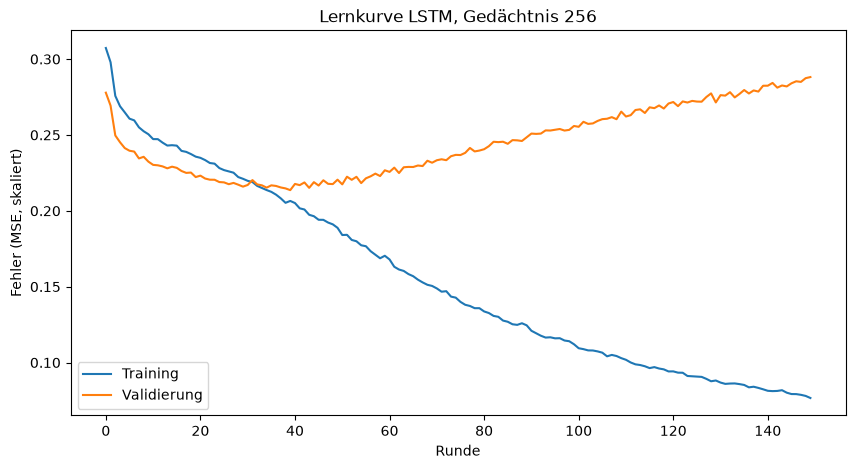

In [44]:
v = pd.DataFrame(verlauf)
ax = v.plot(x="runde", y=["training", "validierung"], figsize=(10, 5))
ax.set_title("Lernkurve LSTM, Gedächtnis 256")
ax.set_xlabel("Runde")
ax.set_ylabel("Fehler (MSE, skaliert)")
ax.legend(["Training", "Validierung"]);

In [45]:
ax.figure.savefig(BILDER / "29_lernkurve_ueberanpassung.png", bbox_inches="tight")

In [46]:
v.loc[v["validierung"].idxmin()]

runde          39.000000
training        0.206509
validierung     0.213629
Name: 39, dtype: float64

Der Validierungsfehler ist in Runde 39 am kleinsten (0,214). Danach fällt nur noch der Trainingsfehler, bis 0,08 in Runde 140, während der Validierungsfehler wieder auf 0,28 steigt. Das ist Überanpassung: Das große Netz lernt die Trainingstage auswendig statt das Verhalten der Stationen.

### 4.3 Early Stopping

Nach jeder Runde wird der beste Stand gemerkt. Nach 20 Runden ohne Verbesserung auf der Validierung ist Schluss, und der beste Stand bleibt. Fertig eingebaut gibt es das in PyTorch nicht, deshalb steht es von Hand da. `copy` braucht es für eine echte Kopie der Gewichte.

In [47]:
import copy

torch.manual_seed(0)
modell = Vorhersage(kanaele=5, gedaechtnis=256).to(geraet)
fehler = torch.nn.MSELoss()
optimierer = torch.optim.Adam(modell.parameters(), lr=0.001)

In [48]:
datei = VORVERSUCHE / "vorhersage_1tag.pt"
if SELBST_TRAINIEREN:
    verlauf = []
    bester_fehler = float("inf")
    geduld = 0

    for runde in range(300):
        modell.train()
        reihenfolge = torch.randperm(len(x_train), device=geraet)
        for start in range(0, len(x_train), 256):
            stapel = reihenfolge[start:start + 256]
            optimierer.zero_grad()
            loss = fehler(modell(x_train[stapel]), y_train[stapel])
            loss.backward()
            optimierer.step()

        modell.eval()
        with torch.no_grad():
            f_train = fehler(modell(x_train), y_train).item()
            f_val = fehler(modell(x_val), y_val).item()
        verlauf.append({"runde": runde, "training": f_train, "validierung": f_val})

        if f_val < bester_fehler:
            bester_fehler = f_val
            bester_stand = copy.deepcopy(modell.state_dict())
            beste_runde = runde
            geduld = 0
        else:
            geduld = geduld + 1
            if geduld == 20:
                break

    modell.load_state_dict(bester_stand)
else:
    gespeichert = gewichte_laden(datei)
    modell.load_state_dict(gespeichert["gewichte"])
    verlauf = gespeichert["verlauf"]
    beste_runde = gespeichert["beste_runde"]
    bester_fehler = verlauf[beste_runde]["validierung"]

print("Abbruch in Runde", verlauf[-1]["runde"])
print("beste Runde:", beste_runde, "  Validierungsfehler:", round(bester_fehler, 4))

Abbruch in Runde 59
beste Runde: 39   Validierungsfehler: 0.2136


In [49]:
if SELBST_TRAINIEREN:
    torch.save({"gewichte": modell.state_dict(), "verlauf": verlauf, "beste_runde": beste_runde}, datei)

Das Training bricht in Runde 59 ab, genommen wird der Stand aus Runde 39. Es stoppt also von selbst, bevor das Netz auswendig lernt, und kein Testwert steuert es. Die Gewichte werden gespeichert (`notebooks/models/vorversuche/vorhersage_1tag.pt`), Notebook 28 lädt sie, statt neu zu lernen.

### 4.4 Schlägt das LSTM die Messlatte?

Der Vergleich in °C, auf denselben Tagen wie das 7-Tage-Mittel aus Abschnitt 3:

In [50]:
x_test = torch.tensor(eingabe[ist_test], dtype=torch.float32, device=geraet)

with torch.no_grad():
    p_val = modell(x_val).cpu().numpy()
    p_test = modell(x_test).cpu().numpy()

In [51]:
rl = pd.DataFrame(X_alle[:, :, 0])
rl["zaehler"] = info["zaehler"]
rl["tag"] = info["tag"]

mittel7 = np.full((len(info), 24), np.nan)
for z, gruppe in rl.groupby("zaehler"):
    g = gruppe.set_index("tag").drop(columns=["zaehler"]).asfreq("D")
    w = g.rolling(7).mean().shift(1)
    mittel7[gruppe.index] = w.loc[gruppe["tag"]].values

In [52]:
m7 = mittel7[morgen]
ok = ~np.isnan(m7).any(axis=1)
wahr = X_alle[morgen][:, :, 0]

for name, teil, p in [("Validierung", ist_val, p_val), ("Test", ist_test, p_test)]:
    o = ok[teil]
    lstm_grad = p[o] * streuung[0] + mittel[0]
    print(name, "LSTM:", np.abs(lstm_grad - wahr[teil][o]).mean().round(2),
          "  7 Tage:", np.abs(m7[teil][o] - wahr[teil][o]).mean().round(2))

Validierung LSTM: 5.07   7 Tage: 5.29
Test LSTM: 4.84   7 Tage: 4.28


Auf der Validierung schlägt das LSTM die Messlatte (5,07 gegen 5,29 K), im Test, dem Sommer 2024, verliert es (4,84 gegen 4,28 K). Für einen Wächter, der jeden Tag vorhersagen soll, ist das zu wenig. Wie sich die Vorhersage verbessern lässt, untersucht Notebook 28. Für den Fingerabdruck zählt etwas anderes: Das Netz muss bei der Vorhersage lernen, was eine Station ausmacht. Ob das gelingt, zeigen die nächsten Abschnitte.

### 4.5 Engpass von 8 Zahlen

Für die Fehlererkennung braucht es einen kurzen Steckbrief je Tag. Der **Encoder**, ein LSTM, liest den Tag und presst ihn auf 8 Zahlen zusammen. Der **Decoder** bekommt nur diese 8 Zahlen und das Wetter von morgen und soll daraus Rücklauf, Durchfluss und Vorlauf von morgen vorhersagen. Klappt das, steckt in den 8 Zahlen, wie sich die Station verhält, und das ist das **Embedding**. Alle drei Kanäle sind Ziel, damit im Steckbrief auch der Durchfluss steckt, denn beim Ventil sieht man den Fehler vor allem dort.

In [53]:
ziel3 = X_s[morgen][:, :, :3].reshape(len(heute), 72)
aussen_morgen = X_s[morgen][:, :, 3]

In [54]:
class Embedding(torch.nn.Module):
    def __init__(self, gedaechtnis, kern):
        super().__init__()
        self.lstm = torch.nn.LSTM(input_size=4, hidden_size=gedaechtnis, batch_first=True)
        self.zum_kern = torch.nn.Linear(gedaechtnis, kern)
        self.decoder = torch.nn.Sequential(
            torch.nn.Linear(kern + 24, 128),
            torch.nn.ReLU(),
            torch.nn.Linear(128, 72),
        )

    def einbetten(self, x):
        ausgabe, (h, c) = self.lstm(x)
        return self.zum_kern(h[-1])

    def forward(self, x, aussen):
        kern = self.einbetten(x)
        return self.decoder(torch.cat([kern, aussen], dim=1))

`zum_kern` ist der Engpass, und `einbetten` gibt nur die 8 Zahlen zurück. Die `ReLU` im Decoder ist ein Knick, der negative Werte auf 0 setzt, damit er nicht nur gerade Zusammenhänge lernen kann.

In [55]:
fehler = torch.nn.MSELoss()

In [56]:
x_tr = torch.tensor(X_s[heute][ist_train], dtype=torch.float32, device=geraet)
a_tr = torch.tensor(aussen_morgen[ist_train], dtype=torch.float32, device=geraet)
y_tr = torch.tensor(ziel3[ist_train], dtype=torch.float32, device=geraet)
x_va = torch.tensor(X_s[heute][ist_val], dtype=torch.float32, device=geraet)
a_va = torch.tensor(aussen_morgen[ist_val], dtype=torch.float32, device=geraet)
y_va = torch.tensor(ziel3[ist_val], dtype=torch.float32, device=geraet)

In [57]:
torch.manual_seed(0)
modell_e = Embedding(gedaechtnis=256, kern=8).to(geraet)
datei = VORVERSUCHE / "embedding_8.pt"
if SELBST_TRAINIEREN:
    optimierer = torch.optim.Adam(modell_e.parameters(), lr=0.001)
    bester_fehler = float("inf")
    geduld = 0

    for runde in range(300):
        modell_e.train()
        reihenfolge = torch.randperm(len(x_tr), device=geraet)
        for start in range(0, len(x_tr), 256):
            stapel = reihenfolge[start:start + 256]
            optimierer.zero_grad()
            loss = fehler(modell_e(x_tr[stapel], a_tr[stapel]), y_tr[stapel])
            loss.backward()
            optimierer.step()

        modell_e.eval()
        with torch.no_grad():
            f_val = fehler(modell_e(x_va, a_va), y_va).item()
        if f_val < bester_fehler:
            bester_fehler = f_val
            bester_stand = copy.deepcopy(modell_e.state_dict())
            beste_runde = runde
            geduld = 0
        else:
            geduld = geduld + 1
            if geduld == 20:
                break

    modell_e.load_state_dict(bester_stand)
else:
    gespeichert = gewichte_laden(datei)
    modell_e.load_state_dict(gespeichert["gewichte"])
    beste_runde = gespeichert["beste_runde"]
    bester_fehler = gespeichert["bester_fehler"]

print("beste Runde:", beste_runde, "  Validierungsfehler:", round(bester_fehler, 4))

beste Runde: 59   Validierungsfehler: 0.1925


In [58]:
if SELBST_TRAINIEREN:
    torch.save({"gewichte": modell_e.state_dict(), "beste_runde": beste_runde, "bester_fehler": bester_fehler}, datei)

Zum Vergleich dasselbe ohne Engpass, mit 256 statt 8 Zahlen:

In [59]:
torch.manual_seed(0)
modell_256 = Embedding(gedaechtnis=256, kern=256).to(geraet)
datei = VORVERSUCHE / "embedding_256.pt"
if SELBST_TRAINIEREN:
    optimierer = torch.optim.Adam(modell_256.parameters(), lr=0.001)
    bester_fehler = float("inf")
    geduld = 0

    for runde in range(300):
        modell_256.train()
        reihenfolge = torch.randperm(len(x_tr), device=geraet)
        for start in range(0, len(x_tr), 256):
            stapel = reihenfolge[start:start + 256]
            optimierer.zero_grad()
            loss = fehler(modell_256(x_tr[stapel], a_tr[stapel]), y_tr[stapel])
            loss.backward()
            optimierer.step()

        modell_256.eval()
        with torch.no_grad():
            f_val = fehler(modell_256(x_va, a_va), y_va).item()
        if f_val < bester_fehler:
            bester_fehler = f_val
            bester_stand = copy.deepcopy(modell_256.state_dict())
            beste_runde = runde
            geduld = 0
        else:
            geduld = geduld + 1
            if geduld == 20:
                break

    modell_256.load_state_dict(bester_stand)
    torch.save({"gewichte": modell_256.state_dict(), "beste_runde": beste_runde, "bester_fehler": bester_fehler}, datei)
else:
    gespeichert = gewichte_laden(datei)
    modell_256.load_state_dict(gespeichert["gewichte"])
    beste_runde = gespeichert["beste_runde"]
    bester_fehler = gespeichert["bester_fehler"]

print("beste Runde:", beste_runde, "  Validierungsfehler:", round(bester_fehler, 4))

beste Runde: 59   Validierungsfehler: 0.1896


In echten Einheiten, für jeden der drei Kanäle:

In [60]:
w = ziel3[ist_val].reshape(-1, 24, 3)
for name, m in [("mit Engpass (8)", modell_e), ("ohne Engpass (256)", modell_256)]:
    with torch.no_grad():
        p = m(x_va, a_va).cpu().numpy().reshape(-1, 24, 3)
    f = np.abs(p - w).mean(axis=(0, 1)) * streuung[:3]
    print(name, "  Rücklauf:", f[0].round(2), "°C   Durchfluss:", f[1].round(1), "l/h   Vorlauf:", f[2].round(2), "°C")

mit Engpass (8)   Rücklauf: 5.22 °C   Durchfluss: 50.0 l/h   Vorlauf: 3.98 °C
ohne Engpass (256)   Rücklauf: 5.07 °C   Durchfluss: 50.5 l/h   Vorlauf: 3.88 °C


Mit Engpass ist der Validierungsfehler nur gut 1 % größer (0,1925 gegen 0,1896), beim Rücklauf 5,22 statt 5,07 K, bei Durchfluss und Vorlauf fast gleich. Fast alles, was das Netz über einen Tag wissen muss, passt also in 8 Zahlen.

Die 8 Zahlen für jeden Tag, nicht nur für die Paare:

In [61]:
teile = []
with torch.no_grad():
    for start in range(0, len(X_s), 4096):
        stueck = torch.tensor(X_s[start:start + 4096], dtype=torch.float32, device=geraet)
        teile.append(modell_e.einbetten(stueck).cpu().numpy())
emb = np.concatenate(teile)
emb.shape

(24684, 8)

## 5 Ein Steckbrief je Station

Der Steckbrief einer Station ist der Durchschnitt der 8 Zahlen über ihre Tage, so wie eine Zeugnisnote aus den einzelnen Noten.

In [62]:
steckbrief = pd.DataFrame(emb).groupby(info["zaehler"]).mean()
steckbrief.shape

(54, 8)

Wie viel Winter steckt in jedem Durchschnitt? Anteil der Tage von November bis März je Station:

In [63]:
winter = info["tag"].dt.month.isin([11, 12, 1, 2, 3])
anteil = winter.groupby(info["zaehler"]).mean()
anteil.describe()

count    54.000000
mean      0.457987
std       0.050265
min       0.416938
25%       0.426136
50%       0.441628
75%       0.482342
max       0.646789
Name: tag, dtype: float64

Zwischen 42 und 65 % der Tage einer Station liegen im Winter. Eine Station mit vielen Wintertagen hätte einen „kälteren“ Steckbrief, ohne dass mit ihr etwas anders ist. Deshalb zählen nur Tage von November bis März, für alle Stationen gleich:

In [64]:
steckbrief_winter = pd.DataFrame(emb[winter.values]).groupby(info["zaehler"][winter].values).mean()
steckbrief_winter.shape

(54, 8)

### 5.1 Wiedererkennung über zwei Winter

Wenn die 8 Zahlen beschreiben, wie sich eine Station verhält, muss man sie ein Jahr später wiedererkennen. Das prüft den Steckbrief ganz ohne Labels. Dafür gibt es je einen Steckbrief aus dem Winter 2022/23 und 2023/24.

In [65]:
w1 = (info["tag"] >= "2022-11-01") & (info["tag"] < "2023-04-01")
w2 = (info["tag"] >= "2023-11-01") & (info["tag"] < "2024-04-01")

s1 = pd.DataFrame(emb[w1.values]).groupby(info["zaehler"][w1].values).mean() 
s2 = pd.DataFrame(emb[w2.values]).groupby(info["zaehler"][w2].values).mean() 

s1.shape, s2.shape

((23, 8), (54, 8))

Der Abstand zweier Steckbriefe ist die Luftlinie zwischen den beiden Listen von 8 Zahlen, klein heißt ähnlich. `cdist` rechnet ihn von jeder Station aus Winter 1 (Zeilen) zu jeder aus Winter 2 (Spalten).

In [66]:
from scipy.spatial.distance import cdist

abstand = cdist(s1, s2)
abstand.shape

(23, 54)

In jeder Zeile die Spalte mit dem kleinsten Abstand. Ist das dieselbe Station, ist sie wiedererkannt:

In [67]:
naechster = s2.index[abstand.argmin(axis=1)]
treffer = naechster == s1.index
treffer.sum()

np.int64(19)

**Ist das ein Verdienst des LSTM?** Zum Vergleich zwei Steckbriefe ohne LSTM: die Wintermittel von Rücklauf, Durchfluss und Vorlauf (3 Zahlen) und der typische Wintertag, jede Stunde einzeln gemittelt (24 × 3 = 72 Zahlen). Beide vorher standardisiert, sonst bestimmt der Durchfluss in l/h den Abstand fast allein.

In [68]:
X = X_alle
tagesmittel = X[:, :, :3].mean(axis=1)
k1 = pd.DataFrame(tagesmittel[w1.values]).groupby(info["zaehler"][w1].values).mean()
k2 = pd.DataFrame(tagesmittel[w2.values]).groupby(info["zaehler"][w2].values).mean()
k2.round(1).head()

,0,1,2
65273846,27.7,61.3,52.8
68956339,48.5,276.0,73.7
68956342,43.2,196.2,69.7
68956344,52.3,132.6,68.3
68956345,51.0,201.5,75.6


In [69]:
m = k2.mean()
s = k2.std()
abstand_k = cdist((k1 - m) / s, (k2 - m) / s)
naechster_k = k2.index[abstand_k.argmin(axis=1)]
(naechster_k == k1.index).sum()

np.int64(13)

In [70]:
profil = X[:, :, :3].reshape(len(X), 72)
p1 = pd.DataFrame(profil[w1.values]).groupby(info["zaehler"][w1].values).mean()
p2 = pd.DataFrame(profil[w2.values]).groupby(info["zaehler"][w2].values).mean()
m = p2.mean()
s = p2.std()
abstand_p = cdist((p1 - m) / s, (p2 - m) / s)
naechster_p = p2.index[abstand_p.argmin(axis=1)]
(naechster_p == p1.index).sum()

np.int64(15)

Mit den 8 LSTM-Zahlen werden 19 von 23 Stationen wiedererkannt, mit 3 Mittelwerten 13 und mit dem typischen Wintertag aus 72 Zahlen 15. Blind geraten wären es 23 × 1/54 ≈ 0,4. Mehr Zahlen allein bringen es also nicht, 72 Zahlen schaffen weniger als die 8 aus dem LSTM.

Eine Station wird gar nicht erkannt. Ihre Wintermittel (Zeile 0 Rücklauf, 1 Durchfluss, 2 Vorlauf):

In [71]:
pd.DataFrame({"Winter 1": k1.loc[68956372], "Winter 2": k2.loc[68956372]}).round(1)

,Winter 1,Winter 2
0,41.4,69.6
1,51.3,318.5
2,62.2,73.1


Der Rücklauf steigt von 41 auf 70 °C, der Durchfluss von 51 auf 318 l/h. Das Wasser läuft durch, ohne seine Wärme abzugeben, wie bei einem offenen Ventil, und bei der Begehung im Oktober 2024 gab es dort einen Ventilbefund. Dass diese Station nicht wiedererkannt wird, ist richtig, denn sie verhält sich seit dem Schaden wirklich anders. Das ist die Idee des Wächters in Notebook 28.

Text(0, 0.5, '')

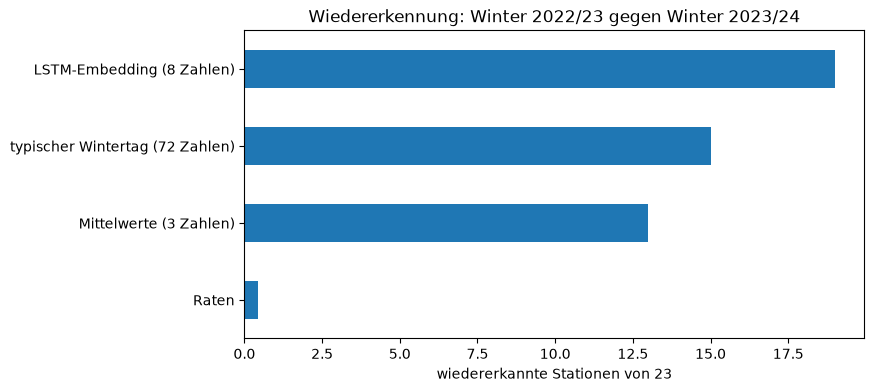

In [72]:
ergebnis = pd.Series({
    "Raten": 23 / 54,
    "Mittelwerte (3 Zahlen)": (naechster_k == k1.index).sum(),
    "typischer Wintertag (72 Zahlen)": (naechster_p == p1.index).sum(),
    "LSTM-Embedding (8 Zahlen)": treffer.sum(),
})
ax = ergebnis.plot.barh(figsize=(8, 4))
ax.set_title("Wiedererkennung: Winter 2022/23 gegen Winter 2023/24")
ax.set_xlabel("wiedererkannte Stationen von 23")
ax.set_ylabel("")

In [73]:
ax.figure.savefig(BILDER / "29_wiedererkennung.png", bbox_inches="tight")

Raten käme auf 0,4, die Mittelwerte auf 13, der typische Wintertag auf 15 und das LSTM auf 19 von 23. Das LSTM erkennt alle 15 Stationen des typischen Wintertags und 4 dazu. Bei 23 Stationen ist das ein deutlicher Hinweis, aber kein Beweis.

### 5.2 Findet der Steckbrief die Befunde?

Genommen wird nur der Steckbrief aus dem Winter 2023/24. Er liegt am nächsten an den Begehungen, alle Stationen haben ihn, und alle Tage liegen vor der Begehung. Vor dem Rechnen war die Erwartung, dass das Embedding Ventil, Dämmung und Überdimensionierung findet, aber nicht Filter, Durchfluss und Temperatur. Geprüft wird mit einer logistischen Regression wie in Notebook 25, mit `StandardScaler` und Leave-one-out, dazu mit dem Zufallstest mit 100 gemischten Durchgängen.

In [74]:
labels = pd.read_csv(ROOT / "data" / "processed" / "modell_labels.csv", index_col="zaehler")
daten = s2.join(labels)
daten.shape

(54, 19)

In [75]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [76]:
modell = make_pipeline(StandardScaler(), LogisticRegression())
befunde = ["ventil", "daemmung", "filter", "durchfluss", "temperatur", "ueberdimensioniert"]

for b in befunde:
    d = daten.dropna(subset=[b])
    vorhersage = cross_val_predict(modell, d[list(range(8))], d[b].astype(int), cv=LeaveOneOut(), method="predict_proba")[:, 1]
    print(b, round(roc_auc_score(d[b].astype(int), vorhersage), 2))

ventil 0.83
daemmung 0.67


filter 0.6
durchfluss 0.3


temperatur 0.28
ueberdimensioniert 0.02


In [77]:
np.random.seed(0)
ergebnis_e = []
for b in befunde:
    d = daten.dropna(subset=[b])
    y = d[b].astype(int)
    v = cross_val_predict(modell, d[list(range(8))], y, cv=LeaveOneOut(), method="predict_proba")[:, 1]
    echt = roc_auc_score(y, v)
    zufall = []
    for i in range(100):
        gemischt = y.sample(frac=1).values
        v = cross_val_predict(modell, d[list(range(8))], gemischt, cv=LeaveOneOut(), method="predict_proba")[:, 1]
        zufall.append(roc_auc_score(gemischt, v))
    ergebnis_e.append({"befund": b, "auc": echt, "zufall_mittel": np.mean(zufall), "zufall_anteil": (np.array(zufall) >= echt).mean()})
ergebnis_e = pd.DataFrame(ergebnis_e)
ergebnis_e.round(2)

,befund,auc,zufall_mittel,zufall_anteil
0,ventil,0.83,0.44,0.00
1,daemmung,0.67,0.44,0.01
2,filter,0.60,0.47,0.18
3,durchfluss,0.30,0.44,0.88
4,temperatur,0.28,0.45,0.92
5,ueberdimensioniert,0.02,0.45,1.00


Echt sind nur Ventil (0,83, in keinem der 100 gemischten Durchgänge erreicht) und Dämmung (0,67, in 1 von 100). Der Filter mit 0,60 kommt in 18 von 100 Durchgängen auch zufällig zustande. Bei der Überdimensionierung (0,02) gibt es kein Signal. Überdimensioniert heißt, dass die Station viel weniger braucht, als ihr Vertrag erlaubt, und den Vertrag kennt das Embedding nicht. Auf 0,98 umdrehen ist nicht erlaubt, die Richtung lernt die Regression selbst.

**Vergleich mit Mittelwerten und Regel.** Sauber ist ein Vergleich, bei dem nur der Steckbrief anders ist: die 3 Mittelwerte aus demselben Winter, gleiche Regression, gleiche Prüfung. Dazu die Regel aus Notebook 25:

In [78]:
daten_k = k2.join(labels)

for b in befunde:
    d = daten_k.dropna(subset=[b])
    vorhersage = cross_val_predict(modell, d[[0, 1, 2]], d[b].astype(int), cv=LeaveOneOut(), method="predict_proba")[:, 1]
    print(b, round(roc_auc_score(d[b].astype(int), vorhersage), 2))

ventil 0.85
daemmung 0.71


filter 0.59
durchfluss 0.14


temperatur 0.32
ueberdimensioniert 0.0


In [79]:
auc_k = []
for b in befunde:
    d = daten_k.dropna(subset=[b])
    vorhersage = cross_val_predict(modell, d[[0, 1, 2]], d[b].astype(int), cv=LeaveOneOut(), method="predict_proba")[:, 1]
    auc_k.append(roc_auc_score(d[b].astype(int), vorhersage))

In [80]:
vergleich = pd.DataFrame({
    "Messlatte (Notebook 25)": [0.88, 0.64, 0.36, 0.50, 0.60, 0.78],
    "3 Mittelwerte, Winter 2023/24": auc_k,
    "Embedding, Winter 2023/24": ergebnis_e["auc"].values,
}, index=["Ventil", "Dämmung", "Filter", "Durchfluss", "Temperatur", "Überdimensionierung"])
vergleich.round(2)

,Messlatte (Notebook 25),"3 Mittelwerte, Winter 2023/24","Embedding, Winter 2023/24"
Ventil,0.88,0.85,0.83
Dämmung,0.64,0.71,0.67
Filter,0.36,0.59,0.60
Durchfluss,0.50,0.14,0.30
Temperatur,0.60,0.32,0.28
Überdimensionierung,0.78,0.00,0.02


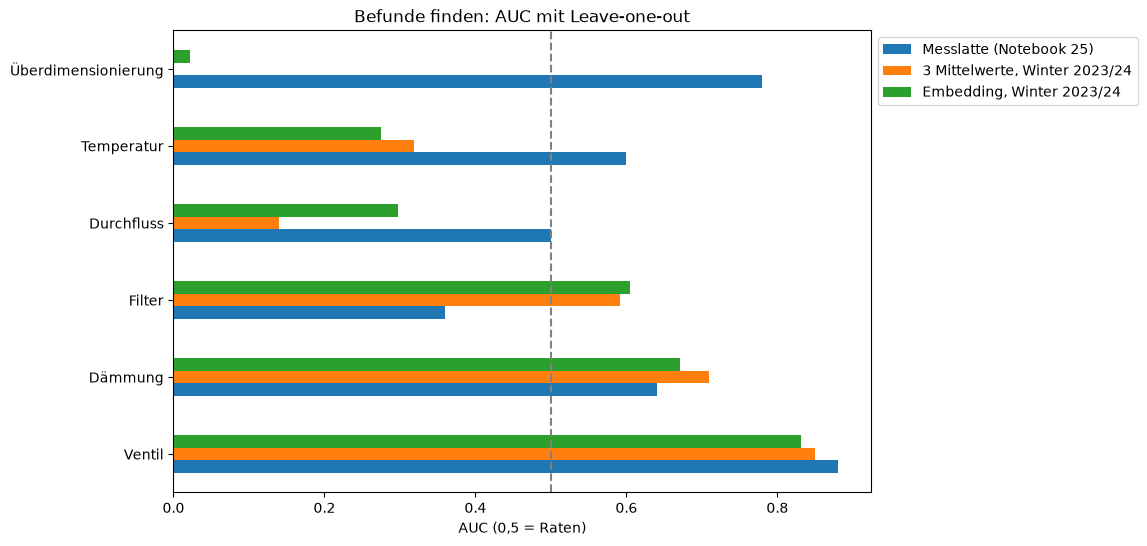

In [81]:
ax = vergleich.plot.barh(figsize=(9, 6))
ax.set_title("Befunde finden: AUC mit Leave-one-out")
ax.set_xlabel("AUC (0,5 = Raten)")
ax.set_ylabel("")
ax.legend(["Messlatte (Notebook 25)", "3 Mittelwerte, Winter 2023/24", "Embedding, Winter 2023/24"],
          loc="upper left", bbox_to_anchor=(1, 1))
ax.axvline(0.5, color="gray", linestyle="--");

In [82]:
ax.figure.savefig(BILDER / "29_befunde_auc.png", bbox_inches="tight")

Beim Ventil kommen die Messlatte auf 0,88, die Mittelwerte auf 0,85 und das Embedding auf 0,83, bei der Dämmung auf 0,64, 0,71 und 0,67. Alle liegen gleichauf, die Unterschiede sind viel kleiner als die Unsicherheit aus Notebook 25 (Dämmung 0,45 bis 0,81). Für das Finden der Befunde bringt der Steckbrief aus dem Winter allein also nichts über die Mittelwerte hinaus. Zum Wiedererkennen braucht es viele kleine Eigenheiten, wie bei einem Fingerabdruck. Ein offenes Ventil ist dagegen eine grobe Abweichung, da reichen klare Kennzahlen.

### 5.3 Warum kein LSTM direkt auf die Befunde?

Naheliegend wäre, ein LSTM gleich auf die Befunde zu trainieren. So viele Gewichte hat das Netz mit Engpass:

In [83]:
sum(p.numel() for p in modell_e.parameters())

283856

Das sind 283.856 Gewichte, aber nur 11 Ventilfälle. Direkt auf die Befunde trainiert, würde das Netz jede Station auswendig lernen. In Notebook 25 reichten schon 10 Spalten Zufallszahlen für eine AUC von 0,75 auf den Lernstationen. Deshalb gibt es die Arbeitsteilung: Das LSTM lernt ohne Befunde aus über 24.000 Tagen, und nur eine logistische Regression mit wenigen Gewichten sieht die Befunde.

### 5.4 Die Größe des Engpasses ohne Befunde wählen

Statt 8 könnte der Engpass auch 4 oder 16 Zahlen haben. Wer die Variante nach den Befunden aussucht, hat aber wieder auf die Antworten geschaut. Ausgewählt wird deshalb nur mit Messungen ohne Befunde, dem Validierungsfehler und der Wiedererkennung. Die Regel steht vor dem Training fest: Gewählt wird die Variante mit dem kleinsten Validierungsfehler.

In [84]:
varianten = []
embeddings = {}

for kern in [4, 8, 16]:
    torch.manual_seed(0)
    m_k = Embedding(gedaechtnis=256, kern=kern).to(geraet)
    datei = VORVERSUCHE / f"engpass_{kern}.pt"
    if SELBST_TRAINIEREN:
        optimierer = torch.optim.Adam(m_k.parameters(), lr=0.001)
        bester_fehler = float("inf")
        geduld = 0

        for runde in range(300):
            m_k.train()
            reihenfolge = torch.randperm(len(x_tr), device=geraet)
            for start in range(0, len(x_tr), 256):
                stapel = reihenfolge[start:start + 256]
                optimierer.zero_grad()
                loss = fehler(m_k(x_tr[stapel], a_tr[stapel]), y_tr[stapel])
                loss.backward()
                optimierer.step()

            m_k.eval()
            with torch.no_grad():
                f_val = fehler(m_k(x_va, a_va), y_va).item()
            if f_val < bester_fehler:
                bester_fehler = f_val
                bester_stand = copy.deepcopy(m_k.state_dict())
                geduld = 0
            else:
                geduld = geduld + 1
                if geduld == 20:
                    break

        m_k.load_state_dict(bester_stand)
        torch.save({"gewichte": m_k.state_dict(), "bester_fehler": bester_fehler}, datei)
    else:
        gespeichert = gewichte_laden(datei)
        m_k.load_state_dict(gespeichert["gewichte"])
        bester_fehler = gespeichert["bester_fehler"]

    teile = []
    with torch.no_grad():
        for start in range(0, len(X_s), 4096):
            stueck = torch.tensor(X_s[start:start + 4096], dtype=torch.float32, device=geraet)
            teile.append(m_k.einbetten(stueck).cpu().numpy())
    embeddings[kern] = np.concatenate(teile)

    e1 = pd.DataFrame(embeddings[kern][w1.values]).groupby(info["zaehler"][w1].values).mean()
    e2 = pd.DataFrame(embeddings[kern][w2.values]).groupby(info["zaehler"][w2].values).mean()
    a = cdist(e1, e2)
    varianten.append({"kern": kern, "validierungsfehler": bester_fehler,
                      "wiedererkannt": (e2.index[a.argmin(axis=1)] == e1.index).sum()})

varianten = pd.DataFrame(varianten)
varianten

,kern,validierungsfehler,wiedererkannt
0,4,0.201333,17
1,8,0.192499,19
2,16,0.190611,20


Bei 8 kommen wieder 0,1925 und 19 heraus wie in 4.5 und 5.1, das Training ist also wiederholbar. Von 4 auf 8 Zahlen ist der Gewinn deutlich (0,201 zu 0,192, 17 zu 19 wiedererkannt), von 8 auf 16 kaum noch (0,191, 20 wiedererkannt). Nach der vorher festgelegten Regel ist das 16.

Erst jetzt die nach der Regel gewählte Variante mit 16 Zahlen bei den Befunden, gleich mit Zufallstest:

In [85]:
e2_16 = pd.DataFrame(embeddings[16][w2.values]).groupby(info["zaehler"][w2].values).mean()
daten_16 = e2_16.join(labels)

In [86]:
np.random.seed(0)
ergebnis_16 = []
for b in befunde:
    d = daten_16.dropna(subset=[b])
    y = d[b].astype(int)
    v = cross_val_predict(modell, d[list(range(16))], y, cv=LeaveOneOut(), method="predict_proba")[:, 1]
    echt = roc_auc_score(y, v)
    zufall = []
    for i in range(100):
        gemischt = y.sample(frac=1).values
        v = cross_val_predict(modell, d[list(range(16))], gemischt, cv=LeaveOneOut(), method="predict_proba")[:, 1]
        zufall.append(roc_auc_score(gemischt, v))
    ergebnis_16.append({"befund": b, "auc": echt, "zufall_anteil": (np.array(zufall) >= echt).mean()})
ergebnis_16 = pd.DataFrame(ergebnis_16)
ergebnis_16.round(2)

,befund,auc,zufall_anteil
0,ventil,0.79,0.00
1,daemmung,0.68,0.03
2,filter,0.69,0.02
3,durchfluss,0.53,0.25
4,temperatur,0.25,0.96
5,ueberdimensioniert,0.35,0.81


Mit 16 Zahlen kommen Ventil auf 0,79 und Dämmung auf 0,68, nicht besser als mit 8 (0,83 und 0,67). Besser vorhersagen und wiedererkennen heißt also nicht besser Fehler finden. Der Filter erreicht 0,69 und ist in 2 von 100 Durchgängen zufällig so gut. Bei 12 Tests (6 Befunde × 2 Varianten) und der Grenze 5 von 100 erwartet man aber 0,6 Zufallstreffer. Weil das nicht vorher erwartet war und nur in einer Variante auftritt, ist es nur ein Hinweis.

**Entscheidung:** Das endgültige Netz bleibt bei 8 Zahlen, obwohl die Regel 16 gewählt hätte. Der Vorteil von 16 liegt im Rauschen, bei den Befunden ist 16 nicht besser, und mit Winter und Sommer ergeben 8 Zahlen schon 16 Merkmale für gut 50 Stationen.

### 5.5 Was aus den Vorversuchen folgt

| Frage | Ergebnis der Vorversuche | Folge für das endgültige Netz |
|---|---|---|
| Wie sieht die Eingabe aus? | ganze Tage als 24 × Kanäle, Skalierung nur aus der Lernzeit | ein Tag als Eingabe, Skalen nur aus Tagen vor der Begehung |
| Wie wird gelernt? | ohne Bremse lernt das Netz ab Runde 40 auswendig | Early Stopping auf der Validierung, dazu Halbieren der Lernrate bei Stillstand |
| Wie groß ist der Engpass? | 8 Zahlen kosten bei der Vorhersage kaum etwas, 16 bringen bei den Befunden nichts | Engpass von 8 Zahlen |
| Taugt der Steckbrief? | erkennt Stationen besser wieder als Mittelwerte (19 gegen 13 von 23) | Steckbrief = mittleres Embedding je Zeitraum |
| Findet er Befunde? | Ventil und Dämmung über Zufall, aber nicht besser als Mittelwerte | Embedding als Merkmal neben Kennzahlen, Prüfung gegen die Sommernacht-Regel |
| LSTM direkt auf Befunde? | 283.856 Gewichte gegen 11 Fälle | nein, nur eine Regression sieht die Befunde |

Das endgültige Netz in den Abschnitten 6 bis 11 hat denselben Grundaufbau: ein Tag als Eingabe, der nächste als Ziel, ein Engpass von 8 Zahlen und Early Stopping. Drei Dinge sind anders, jeweils aus einem Grund.

Es bekommt sechs statt vier Größen, Leistung und Spreizung kommen dazu. Sie hängen physikalisch mit dem Durchfluss zusammen (Leistung ≈ Durchfluss × Spreizung), und ein offenes Ventil zeigt sich gerade darin, dass Wasser mit kleiner Spreizung fließt, ohne dass Leistung abgenommen wird. Durchfluss und Leistung werden außerdem je Zähler durch sein 95-%-Quantil geteilt, sonst sähe gleiches Verhalten bei einem großen und einem kleinen Haus verschieden aus. Und das Netz ist kleiner und hat einen LSTM-Decoder: 96 statt 256 Gedächtniszahlen, und der Decoder bekommt zu jeder Stunde die Außentemperatur. Mit 116.941 statt 283.856 Gewichten erkennt es Stationen genauso wieder (83 %, Abschnitt 9).

Dazu kommt der Sommer, denn das Ventilsignal liegt in den Sommernächten (Notebook 25). Der Steckbrief einer Station besteht deshalb aus 8 Zahlen für den Winter 2023/24 und 8 für den Sommer 2024, zusammen 16.

## 6 Das endgültige Netz: Daten laden und ansehen

Die Zelle lädt die drei Dateien aus Notebook 25, Stundenwerte, Labels und Kennzahlen.

In [87]:
stunden = pd.read_parquet(PROCESSED / "modell_stunden.parquet")
labels = pd.read_csv(PROCESSED / "modell_labels.csv", index_col="zaehler", parse_dates=["erste_begehung"])
kz = pd.read_csv(PROCESSED / "modell_kennzahlen.csv", index_col="zaehler")
print(f"stunden: {stunden.shape[0]:,} Zeilen × {stunden.shape[1]} Spalten, {stunden['zaehler'].nunique()} Zähler")
print(f"labels:  {labels.shape[0]} begangene Zähler, kz: {kz.shape[0]} Zähler × {kz.shape[1]} Kennzahlen")
stunden.dropna().sample(5, random_state=SEED).sort_values(["zaehler", "timestamp"])

stunden: 2,128,400 Zeilen × 8 Spalten, 93 Zähler
labels:  56 begangene Zähler, kz: 91 Zähler × 16 Kennzahlen


,zaehler,timestamp,vorlauf,ruecklauf,spreizung,durchfluss,leistung,aussen
12366,53198226,2023-04-01 05:00:00,63.8,55.9,7.9,0.0,0.00,9.8
261149,68956344,2024-12-04 17:00:00,68.4,58.6,9.7,242.0,2.77,3.1
320762,68956347,2024-05-07 10:00:00,72.5,41.0,31.5,0.0,0.00,12.3
617238,68956361,2024-06-27 09:00:00,55.7,46.4,9.3,0.0,0.00,20.8
1736256,80912172,2024-12-27 23:00:00,42.7,41.5,1.1,0.0,0.00,-3.2


Die Stundenwerte enthalten 93 Zähler, 56 begangene Zähler haben ein Label, und Kennzahlen gibt es für 91 Zähler. Die fünf Beispielzeilen zeigen das Rohmaterial des Netzes: je Stunde Vorlauf, Rücklauf, Spreizung (Vorlauf minus Rücklauf), Durchfluss, Leistung und Außentemperatur.

### 6.1 Vollständige Tage als Feld

Das Netz liest ganze Tage. Jeder vollständige Tag wird eine Tabelle mit 24 Zeilen für die Stunden und 6 Spalten für die Größen, und alle Tage zusammen ergeben ein dreidimensionales Feld aus Tagen × 24 × 6.

In [88]:
KANAELE = ["leistung", "durchfluss", "spreizung", "vorlauf", "ruecklauf", "aussen"]
stunden = stunden.dropna(subset=KANAELE)
stunden["tag"] = stunden["timestamp"].dt.floor("D")
voll = stunden.groupby(["zaehler", "tag"])["timestamp"].transform("size") == 24
stunden = stunden[voll].sort_values(["zaehler", "timestamp"])

werte = stunden[KANAELE].to_numpy(dtype=np.float32).reshape(-1, 24, len(KANAELE))
tage = stunden[["zaehler", "tag"]].iloc[::24].reset_index(drop=True)

#Je Zähler: bis wann gilt "vor der Begehung"? Und gehört er zu den begangenen HAST?
grenze = labels["erste_begehung"].clip(upper=STICHTAG)
tage["vorher"] = tage["tag"] < tage["zaehler"].map(grenze).fillna(STICHTAG)
tage["begangen"] = tage["zaehler"].isin(labels.index)
print(f"Feld: {werte.shape[0]:,} Tage × {werte.shape[1]} Stunden × {werte.shape[2]} Größen")
pd.crosstab(tage["begangen"].map({True: "begangene HAST", False: "nie begangen"}),
            tage["vorher"].map({True: "vor der Begehung", False: "danach"}), margins=True, margins_name="Summe")

Feld: 67,840 Tage × 24 Stunden × 6 Größen


vorher,danach,vor der Begehung,Summe
begangen,,,
begangene HAST,17568,24684,42252
nie begangen,9781,15807,25588
Summe,27349,40491,67840


Stunden mit fehlenden Werten fallen weg, es bleiben nur Tage mit allen 24 Stunden, zusammen 67.840 Tage. `reshape(-1, 24, 6)` baut das Feld. Das klappt, weil die Tabelle nach Zähler und Zeit sortiert ist und je 24 Zeilen einen Tag bilden. `tage` merkt sich je Tag Zähler und Datum, ob der Tag vor der ersten Begehung liegt und ob der Zähler begangen wurde. Die Kreuztabelle zeigt, woraus das Netz lernen darf, nämlich aus den begangenen HAST vor der Begehung (24.684 Tage).

### 6.2 Skalierung

Netze lernen schlecht, wenn eine Größe in Hunderten wie der Durchfluss und eine andere in Zehnern wie die Temperatur gemessen wird. Leistung und Durchfluss werden deshalb je Zähler durch sein 95-%-Quantil geteilt, so sieht gleiches Verhalten bei großen und kleinen Häusern gleich aus. Temperaturen und Spreizung werden für alle gleich standardisiert, also Mittelwert abziehen und durch die Streuung teilen. 65 °C Rücklauf ist in jedem Haus schlecht, und das soll das Netz sehen. Die Skalen kommen nur aus Tagen vor den Begehungen. Für nie begangene Zähler wird ihr eigenes 95-%-Quantil genauso bestimmt, damit das Netz sie übersetzen kann.

In [89]:
x = werte.copy()
vorher = tage["vorher"].to_numpy()
stunde_vorher = np.repeat(vorher, 24)          #dieselbe Markierung je Stunde (gleiche Reihenfolge wie im Feld)
teiler, mittel, streuung, skalen = {}, {}, {}, {}
for i, kanal in enumerate(KANAELE):
    if kanal in ("leistung", "durchfluss"):
        teiler[kanal] = stunden[stunde_vorher].groupby("zaehler")[kanal].quantile(0.95).clip(lower=1e-3)
        je_tag = tage["zaehler"].map(teiler[kanal]).fillna(1.0).to_numpy(dtype=np.float32)
        x[:, :, i] = werte[:, :, i] / je_tag[:, None]
        skalen[kanal] = "Wert / 95-%-Quantil des Zählers"
    else:
        mittel[kanal], streuung[kanal] = werte[vorher, :, i].mean(), werte[vorher, :, i].std()
        x[:, :, i] = (werte[:, :, i] - mittel[kanal]) / streuung[kanal]
        skalen[kanal] = f"(Wert − {mittel[kanal]:.1f}) / {streuung[kanal]:.1f}"
pd.DataFrame({"Skalierung": pd.Series(skalen),
              "Mittel danach": pd.Series(x[vorher].mean(axis=(0, 1)), index=KANAELE).round(2),
              "Streuung danach": pd.Series(x[vorher].std(axis=(0, 1)), index=KANAELE).round(2)})

,Skalierung,Mittel danach,Streuung danach
leistung,Wert / 95-%-Quantil des Zählers,0.27,0.37
durchfluss,Wert / 95-%-Quantil des Zählers,0.35,0.40
spreizung,(Wert − 15.9) / 13.6,-0.00,1.00
vorlauf,(Wert − 63.2) / 15.5,-0.00,1.00
ruecklauf,(Wert − 47.3) / 15.8,0.00,1.00
aussen,(Wert − 11.7) / 8.3,0.00,1.00


Nach dem Teilen liegen typische Werte für Leistung und Durchfluss zwischen 0 und 1. Die Tabelle zeigt die Rechnung je Größe und prüft das Ergebnis, Temperaturen und Spreizung haben danach Mittel 0 und Streuung 1.

### 6.3 Lernbeispiele: heute und morgen

Ein Lernbeispiel ist ein Paar aus zwei aufeinanderfolgenden vollständigen Tagen desselben Zählers. Das Netz bekommt heute komplett und von morgen nur die Außentemperatur, denn die steht im Wetterbericht, das Verhalten der Station nicht. Für den Vergleich in Abschnitt 9 gibt es zwei weitere Varianten, dieselbe Aufgabe auf allen Zählern und „Tag nachbilden“ als Autoencoder, bei dem Ein- und Ausgabe derselbe Tag sind. `beispiele()` stellt für jede Variante die passenden Tage zusammen. Validiert wird auf ganzen Kalenderwochen, weil der 14. Januar einer Station dem 13. fast genau gleicht und einzelne Tage in der Validierung die Prüfung zu leicht machen würden.

In [90]:
folgetag = ((tage["zaehler"].shift(-1) == tage["zaehler"])
            & (tage["tag"].shift(-1) == tage["tag"] + pd.Timedelta(days=1))).to_numpy()


def beispiele(nur_begangene, aufgabe):
    #Eingangstage und Zieltage für eine Variante, dazu die Markierung der Validierungswochen
    erlaubt = vorher & (tage["begangen"].to_numpy() if nur_begangene else True)
    if aufgabe == "vorhersagen":
        heute = np.flatnonzero(folgetag & erlaubt & np.roll(erlaubt, -1))
        ziel_tag = heute + 1
    else:  #nachbilden: Eingang und Ziel sind derselbe Tag
        heute = np.flatnonzero(erlaubt)
        ziel_tag = heute
    woche = tage.loc[ziel_tag, "tag"].dt.to_period("W").astype(str).to_numpy()
    wochen = np.unique(woche)
    val_wochen = np.random.default_rng(SEED).choice(wochen, size=int(0.1 * len(wochen)), replace=False)
    return heute, ziel_tag, np.isin(woche, val_wochen)


VARIANTEN = {
    "begangen":    {"nur_begangene": True,  "aufgabe": "vorhersagen", "text": "nächsten Tag vorhersagen, nur begangene HAST (Hauptmodell)"},
    "alle":        {"nur_begangene": False, "aufgabe": "vorhersagen", "text": "nächsten Tag vorhersagen, alle HAST"},
    "nachbilden":  {"nur_begangene": True,  "aufgabe": "nachbilden",  "text": "Tag nachbilden (Autoencoder), nur begangene HAST"},
}
zeilen = []
for name, v in VARIANTEN.items():
    heute, ziel_tag, ist_val = beispiele(v["nur_begangene"], v["aufgabe"])
    zeilen.append({"Variante": name, "Beschreibung": v["text"], "Beispiele": len(heute),
                   "davon Validierung": int(ist_val.sum()), "Zähler": tage.loc[heute, "zaehler"].nunique()})
pd.DataFrame(zeilen).set_index("Variante")

,Beschreibung,Beispiele,davon Validierung,Zähler
Variante,,,,
begangen,"nächsten Tag vorhersagen, nur begangene HAST (...",24236,1987,54
alle,"nächsten Tag vorhersagen, alle HAST",39711,3318,90
nachbilden,"Tag nachbilden (Autoencoder), nur begangene HAST",24684,1999,54


`folgetag` ist wahr, wenn der nächste Eintrag derselbe Zähler am nächsten Kalendertag ist, nur dann gibt es ein echtes Paar. `beispiele()` nimmt nur Tage vor der Begehung, beim Hauptmodell nur von begangenen Zählern, und legt 10 % der Kalenderwochen als Validierung fest. Das Hauptmodell hat 24.236 Beispiele von 54 Zählern, die Variante „alle“ 39.711 von 90 Zählern. Dafür kommen beim Hauptmodell nur Stationen vor, deren Zustand durch die Begehung bekannt ist.

## 7 Das Netz

```
heute (24 × 6) ──► LSTM-Encoder (96) ──► 8 Zahlen = Embedding
                                              │
          Außentemperatur morgen (24 × 1) ──► LSTM-Decoder (96) ──► morgen (24 × 5)
```

Der Encoder liest den Tag Stunde für Stunde und fasst ihn in seinem letzten Zustand zusammen, eine lineare Schicht presst das auf acht Zahlen. Der Decoder bekommt diese acht Zahlen zu jeder Stunde des Zieltags, dazu die Außentemperatur dieser Stunde, und gibt fünf Größen aus. Beim Autoencoder ist der Zieltag derselbe Tag.

In [91]:
class LSTMEmbedding(nn.Module):
    def __init__(self, n_ein=6, n_aus=5, versteckt=96, kern=8):
        super().__init__()
        self.encoder = nn.LSTM(n_ein, versteckt, batch_first=True)
        self.zum_kern = nn.Linear(versteckt, kern)
        self.vom_kern = nn.Linear(kern, versteckt)
        self.decoder = nn.LSTM(versteckt + 1, versteckt, batch_first=True)
        self.ausgang = nn.Linear(versteckt, n_aus)

    def einbetten(self, tag):
        _, (zustand, _) = self.encoder(tag)
        return self.zum_kern(zustand[-1])

    def forward(self, tag, aussen_ziel):
        kern = self.einbetten(tag)
        je_stunde = self.vom_kern(kern).unsqueeze(1).repeat(1, aussen_ziel.shape[1], 1)
        y, _ = self.decoder(torch.cat([je_stunde, aussen_ziel], dim=2))
        return self.ausgang(y)


print(LSTMEmbedding())
print(f"{sum(p.numel() for p in LSTMEmbedding().parameters()):,} lernbare Gewichte")

LSTMEmbedding(
  (encoder): LSTM(6, 96, batch_first=True)
  (zum_kern): Linear(in_features=96, out_features=8, bias=True)
  (vom_kern): Linear(in_features=8, out_features=96, bias=True)
  (decoder): LSTM(97, 96, batch_first=True)
  (ausgang): Linear(in_features=96, out_features=5, bias=True)
)
116,941 lernbare Gewichte


Das Netz besteht aus zwei `nn.LSTM` und drei `nn.Linear`, zusammen 116.941 lernbare Gewichte. `einbetten()` liefert die acht Zahlen, und nach dem Training wird nur diese Funktion gebraucht, um jeden Tag zu übersetzen. `forward()` ist der ganze Weg vom Eingangstag zum Zieltag und dient nur dem Lernen.

## 8 Training des Hauptmodells (nur begangene HAST)

Gelernt wird mit dem Adam-Optimierer auf den mittleren quadratischen Fehler. Nach jeder Runde durch alle Trainingsbeispiele wird der Fehler auf der Validierung gemessen. Wird er 20 Runden lang nicht besser, ist Schluss (Early Stopping), und der beste Stand bleibt. Stagniert er 5 Runden, wird die Lernrate halbiert.

In [92]:
def trainieren(heute, ziel_tag, ist_val, max_runden=300, geduld=20, stapel=512):
    torch.manual_seed(SEED)
    modell = LSTMEmbedding().to(GERAET)
    opt = torch.optim.Adam(modell.parameters(), lr=3e-3)
    plan = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5, min_lr=1e-5)
    e = torch.tensor(x[heute]).to(GERAET)
    z = torch.tensor(x[ziel_tag][:, :, :5]).to(GERAET)
    a = torch.tensor(x[ziel_tag][:, :, 5:]).to(GERAET)
    lern, val = np.flatnonzero(~ist_val), torch.tensor(np.flatnonzero(ist_val), device=GERAET)
    verlauf, bester, bester_zustand, ohne_besserung = [], np.inf, None, 0
    for runde in range(max_runden):
        modell.train()
        summe = 0.0
        for teil in np.array_split(np.random.default_rng(runde).permutation(lern), max(1, len(lern) // stapel)):
            i = torch.tensor(teil, device=GERAET)
            verlust = nn.functional.mse_loss(modell(e[i], a[i]), z[i])
            opt.zero_grad()
            verlust.backward()
            opt.step()
            summe += verlust.item() * len(teil)
        modell.eval()
        with torch.no_grad():
            v = nn.functional.mse_loss(modell(e[val], a[val]), z[val]).item()
        verlauf.append({"runde": runde + 1, "training": summe / len(lern), "validierung": v})
        plan.step(v)
        if v < bester - 1e-5:
            bester, ohne_besserung = v, 0
            bester_zustand = {k: w.detach().clone() for k, w in modell.state_dict().items()}
        else:
            ohne_besserung += 1
            if ohne_besserung >= geduld:
                break
    modell.load_state_dict(bester_zustand)
    return modell, pd.DataFrame(verlauf)


def laden_oder_trainieren(name):
    datei = MODELLE / f"lstm_embedding_{name}.pt"
    v = VARIANTEN[name]
    heute, ziel_tag, ist_val = beispiele(v["nur_begangene"], v["aufgabe"])
    if SELBST_TRAINIEREN:
        start = time.time()
        modell, verlauf = trainieren(heute, ziel_tag, ist_val)
        torch.save({"gewichte": modell.state_dict(), "verlauf": verlauf.to_dict("list")}, datei)
        print(f"{name:11s} trainiert in {time.time() - start:.0f} s, gespeichert in {datei.relative_to(ROOT)}")
    else:
        modell = LSTMEmbedding().to(GERAET)
        gespeichert = gewichte_laden(datei)
        modell.load_state_dict(gespeichert["gewichte"])
        verlauf = pd.DataFrame(gespeichert["verlauf"])
        print(f"{name:11s} Gewichte geladen aus {datei.relative_to(ROOT)}")
    modell.eval()
    return modell, verlauf, (heute, ziel_tag, ist_val)


modell, verlauf, (heute, ziel_tag, ist_val) = laden_oder_trainieren("begangen")
beste_runde = int(verlauf.loc[verlauf["validierung"].idxmin(), "runde"])
print(f"{len(verlauf)} Runden, bester Validierungsfehler {verlauf['validierung'].min():.4f} in Runde {beste_runde}")

begangen    Gewichte geladen aus notebooks/models/lstm_embedding_begangen.pt
92 Runden, bester Validierungsfehler 0.1772 in Runde 72


`trainieren()` ist die übliche PyTorch-Schleife: Stapel von 512 Beispielen durchs Netz schicken, Fehler berechnen, `backward()`, `step()`. Nach jeder Runde wird der beste Stand gemerkt. `laden_oder_trainieren()` lädt die gespeicherten Gewichte oder lernt mit `SELBST_TRAINIEREN = True` neu. Die Lernkurve wird mitgespeichert, damit ein zweiter Lauf dieselbe Kurve zeigt. Das Training dauert 11 Sekunden und 92 Runden, der beste Validierungsfehler liegt bei 0,1772 in Runde 72.

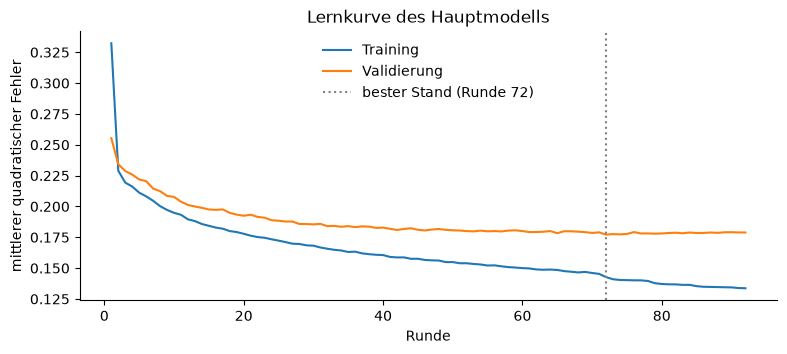

In [93]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(verlauf["runde"], verlauf["training"], label="Training")
ax.plot(verlauf["runde"], verlauf["validierung"], label="Validierung")
ax.axvline(beste_runde, color="grey", ls=":", label=f"bester Stand (Runde {beste_runde})")
ax.set_xlabel("Runde")
ax.set_ylabel("mittlerer quadratischer Fehler")
ax.set_title("Lernkurve des Hauptmodells")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Die Lernkurve zeigt, wie der Fehler über die Runden sinkt. Laufen Training und Validierung weit auseinander, lernt das Netz die Trainingstage auswendig (Überanpassung).

Der Validierungsfehler fällt in den ersten 20 Runden steil und wird ab etwa Runde 40 flach. Der beste Stand liegt in Runde 72, und nach 20 Runden ohne Besserung bricht das Training in Runde 92 ab. Danach sinkt nur noch der Trainingsfehler, ab hier würde das Netz anfangen, die Trainingstage auswendig zu lernen. Das Training dauert auf der GPU rund 11 Sekunden, weil nur die begangenen HAST gelernt werden (24.236 statt 39.711 Beispiele).

Validierungsfehler je Tag: Median 0.141; gezeigt wird ein Wintertag mit 0.120


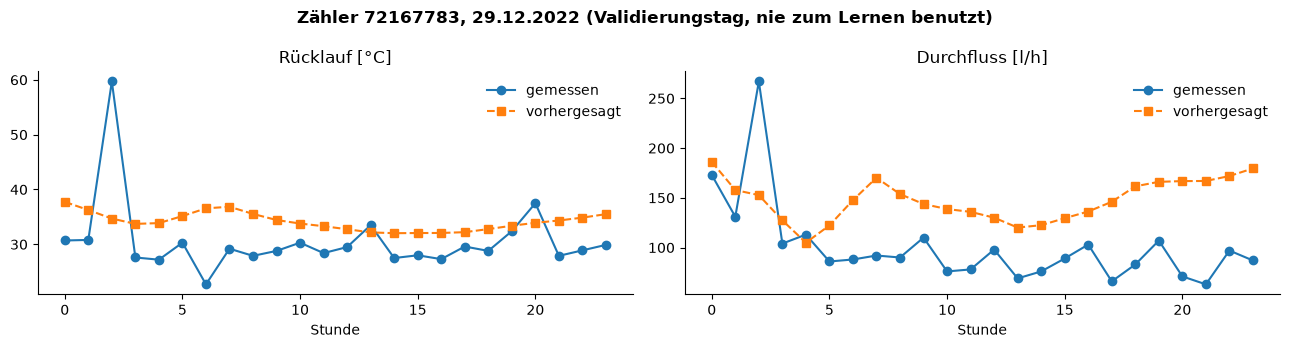

In [94]:
#Ein typischer Validierungstag im Winter: der mit dem mittleren Vorhersagefehler
val_index = np.flatnonzero(ist_val)
with torch.no_grad():
    val_vorhersage = modell(torch.tensor(x[heute[val_index]]).to(GERAET),
                            torch.tensor(x[ziel_tag[val_index]][:, :, 5:]).to(GERAET)).cpu().numpy()
fehler_je_tag = ((val_vorhersage - x[ziel_tag[val_index]][:, :, :5]) ** 2).mean(axis=(1, 2))
im_winter = tage.loc[ziel_tag[val_index], "tag"].dt.month.isin([12, 1, 2]).to_numpy()
kandidaten = np.flatnonzero(im_winter)
mitte = kandidaten[np.argsort(fehler_je_tag[kandidaten])[len(kandidaten) // 2]]
vorhersage, tag_index = val_vorhersage[mitte], ziel_tag[val_index[mitte]]
print(f"Validierungsfehler je Tag: Median {np.median(fehler_je_tag):.3f}; gezeigt wird ein Wintertag mit {fehler_je_tag[mitte]:.3f}")
zaehler, datum = tage.loc[tag_index, "zaehler"], tage.loc[tag_index, "tag"]
i_rl, i_fl = KANAELE.index("ruecklauf"), KANAELE.index("durchfluss")
rl_vorh = vorhersage[:, i_rl] * streuung["ruecklauf"] + mittel["ruecklauf"]
fl_vorh = vorhersage[:, i_fl] * teiler["durchfluss"][zaehler]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].plot(werte[tag_index, :, i_rl], "o-", label="gemessen")
axes[0].plot(rl_vorh, "s--", label="vorhergesagt")
axes[0].set_title("Rücklauf [°C]")
axes[1].plot(werte[tag_index, :, i_fl], "o-", label="gemessen")
axes[1].plot(fl_vorh, "s--", label="vorhergesagt")
axes[1].set_title("Durchfluss [l/h]")
for ax in axes:
    ax.set_xlabel("Stunde")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Zähler {zaehler}, {datum:%d.%m.%Y} (Validierungstag, nie zum Lernen benutzt)", fontweight="bold")
fig.tight_layout()
plt.show()

Die Zelle sagt alle Validierungstage vorher und zeigt unter den Wintertagen den mit dem mittleren Fehler, also kein Glanzbeispiel und keinen Ausreißer (Fehler 0,120, Median aller Validierungstage 0,141). Die Skalierung wird zurück in °C und l/h gerechnet. Das Netz soll den groben Verlauf treffen, nicht jede Stunde. Für das Embedding zählt, dass es das Typische einer Station erfasst.

## 9 Embeddings, Wiedererkennung und Vergleich der drei Varianten

Ab jetzt wird nur der Encoder gebraucht. Jeder vollständige Tag wird in seine acht Zahlen übersetzt, auch Tage nie begangener Zähler, und je Zähler und Zeitraum beschreibt der Mittelwert über alle Tage die Station. Die Wiedererkennung prüft ohne Labels, ob diese Beschreibung taugt: Liegt das Winter-Embedding 23/24 einer Station ihrem eigenen von 22/23 am nächsten? Raten träfe bei n Stationen in 1/n der Fälle.

In [95]:
ZEITRAEUME = {"w2223": ("2022-10-01", "2023-04-01"), "w2324": ("2023-10-01", "2024-04-01"), "s2024": ("2024-06-01", "2024-09-01")}
MIN_TAGE = 30


def embeddings(modell):
    with torch.no_grad():
        kerne = torch.cat([modell.einbetten(torch.tensor(x[i:i + 4096]).to(GERAET)).cpu()
                           for i in range(0, len(x), 4096)]).numpy()
    kern_tab = pd.concat([tage[["zaehler", "tag", "vorher"]], pd.DataFrame(kerne, columns=[f"z{i}" for i in range(8)])], axis=1)
    teile = []
    for name, (von, bis) in ZEITRAEUME.items():
        t = kern_tab[(kern_tab["tag"] >= von) & (kern_tab["tag"] < bis) & kern_tab["vorher"]]
        m = t.groupby("zaehler")[[f"z{i}" for i in range(8)]].mean()
        teile.append(m[t.groupby("zaehler").size() >= MIN_TAGE].add_prefix(f"lstm_{name}_"))
    return pd.concat(teile, axis=1)


def wiedererkennung(emb):
    beide = emb[[f"lstm_w2223_z{i}" for i in range(8)] + [f"lstm_w2324_z{i}" for i in range(8)]].dropna()
    alt, neu = beide.filter(like="w2223").to_numpy(), beide.filter(like="w2324").to_numpy()
    abstand = np.linalg.norm(neu[:, None, :] - alt[None, :, :], axis=2)   #Station i (23/24) gegen Station j (22/23)
    rang = pd.Series((abstand < np.diag(abstand)[:, None]).sum(axis=1) + 1, index=beide.index)
    return rang                                                          #1 = die eigene Station ist die nächste


embedding = embeddings(modell)
rang = wiedererkennung(embedding)
print(f"Embeddings für {len(embedding)} Zähler; je Zeitraum vorhanden: "
      + ", ".join(f"{n} {embedding[f'lstm_{n}_z0'].notna().sum()}" for n in ZEITRAEUME))
gruppe = rang.index.isin(labels.index)
print(f"Wiedererkennung über zwei Winter: {(rang == 1).mean():.0%} von {len(rang)} Stationen (Zufall {1 / len(rang):.0%})")
print(f"  begangene HAST (im Training):  {(rang[gruppe] == 1).mean():.0%} von {gruppe.sum()}")
print(f"  nie begangene (nie gesehen):    {(rang[~gruppe] == 1).mean():.0%} von {(~gruppe).sum()}")
embedding.round(2).head()

Embeddings für 90 Zähler; je Zeitraum vorhanden: w2223 41, w2324 87, s2024 82
Wiedererkennung über zwei Winter: 83% von 41 Stationen (Zufall 2%)
  begangene HAST (im Training):  87% von 23
  nie begangene (nie gesehen):    78% von 18


,lstm_w2223_z0,lstm_w2223_z1,lstm_w2223_z2,lstm_w2223_z3,lstm_w2223_z4,lstm_w2223_z5,lstm_w2223_z6,lstm_w2223_z7,lstm_w2324_z0,lstm_w2324_z1,lstm_w2324_z2,lstm_w2324_z3,lstm_w2324_z4,lstm_w2324_z5,lstm_w2324_z6,lstm_w2324_z7,lstm_s2024_z0,lstm_s2024_z1,lstm_s2024_z2,lstm_s2024_z3,lstm_s2024_z4,lstm_s2024_z5,lstm_s2024_z6,lstm_s2024_z7
zaehler,,,,,,,,,,,,,,,,,,,,,,,,
53198226,-0.37,0.15,-0.29,0.32,-0.28,0.14,-0.01,-0.91,-0.03,-0.16,-0.16,0.40,-0.34,0.22,-0.24,-1.12,-0.43,0.54,-0.30,-0.43,0.44,-0.04,0.20,-0.67
58177363,-0.12,-0.09,0.16,0.62,-0.55,0.16,-0.22,-0.79,0.04,-0.03,0.17,0.55,-0.52,0.14,-0.08,-0.80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
58177384,-0.26,-0.01,-0.75,0.04,0.23,0.03,-0.79,-0.91,-0.06,-0.04,-0.32,-0.21,-0.25,-0.01,-0.32,-0.78,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
61620222,-0.22,0.07,-0.03,0.48,-0.09,-0.12,0.13,0.07,-0.08,0.03,0.11,0.48,-0.27,-0.15,0.20,0.14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
65273846,0.40,-0.66,1.12,0.37,-1.12,-0.30,-0.10,-0.26,0.33,-0.49,1.20,0.18,-1.08,-0.12,0.17,0.10,0.08,0.42,0.83,-0.17,-0.70,0.18,0.51,1.13


`embeddings()` übersetzt alle Tage mit `modell.einbetten()` und mittelt je Zähler über drei Zeiträume, Winter 22/23, Winter 23/24 und Sommer 2024. Dabei zählen nur Tage vor der Begehung und nur Zähler mit mindestens 30 Tagen. `wiedererkennung()` misst den Abstand jedes 23/24-Embeddings zu allen 22/23-Embeddings und zählt, wie viele fremde Stationen näher liegen als die eigene. Getrennt ausgewiesen werden Stationen aus dem Training und nie begangene, die das Netz nie gesehen hat. Für diese ist die Wiedererkennung ein echter Test.

83 % der 41 Stationen mit zwei Wintern werden wiedererkannt, ihr Embedding 23/24 liegt dem eigenen von 22/23 näher als jedem fremden. Zufall wären 2 %. Auch nie begangene Stationen werden meist erkannt, 78 % von 18 gegen 87 % von 23 bei den begangenen. Der Abstand entspricht etwa zwei Stationen. Das passt dazu, dass das Netz allgemein gelernt hat, wie sich eine Station verhält, und nicht die begangenen Stationen auswendig. Die Vorgabe der Betreuung ist hier also kein Nachteil, das Netz aus den begangenen HAST beschreibt auch die anderen.

### 9.1 Vorgabe und Alternativen im direkten Vergleich

Dieselbe Rechnung gibt es für die beiden anderen Varianten. Jede Variante wird gleich geprüft, mit der Wiedererkennung ohne Labels und mit der verschachtelten Fehlererkennung aus Abschnitt 10, nur mit den Embeddings.

In [96]:
def verschachtelt(X, y, gruppen=None):
    #Vorhersage je Station aus einem Modell, das diese Station nie gesehen hat
    pipeline = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                             LogisticRegression(class_weight="balanced", max_iter=5000))
    suche = GridSearchCV(pipeline, {"logisticregression__C": [0.03, 0.1, 0.3, 1.0]},
                         cv=StratifiedKFold(4, shuffle=True, random_state=SEED), scoring="roc_auc")
    aussen = LeaveOneOut() if gruppen is None else LeaveOneGroupOut()
    return cross_val_predict(suche, X, y, cv=aussen, groups=gruppen, method="predict_proba", n_jobs=-1)[:, 1]


def auc_mit_intervall(y, score, n=2000):
    y, score = np.asarray(y), np.asarray(score)
    rng = np.random.default_rng(SEED)
    ziehungen = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            ziehungen.append(roc_auc_score(y[i], score[i]))
    return roc_auc_score(y, score), np.quantile(ziehungen, 0.025), np.quantile(ziehungen, 0.975)


def precision_at_k(y, score, k=10):
    return np.asarray(y)[np.argsort(-np.asarray(score))[:k]].mean()


LSTM_WINTER = [f"lstm_w2324_z{i}" for i in range(8)]
LSTM_SOMMER = [f"lstm_s2024_z{i}" for i in range(8)]
alle_embeddings = {"begangen": embedding}
for name in ("alle", "nachbilden"):
    m, verl, _ = laden_oder_trainieren(name)
    alle_embeddings[name] = embeddings(m)

#gleiche Prüfbasis für alle Varianten: begangene Zähler mit Winter-Embedding und Sommerwerten in jeder Variante
basis_index = labels.index.intersection(kz.dropna(subset=["sommer_durchlauf_anteil"]).index)
for emb in alle_embeddings.values():
    basis_index = basis_index.intersection(emb.dropna(subset=LSTM_WINTER).index)

zeilen = []
for name, emb in alle_embeddings.items():
    r = wiedererkennung(emb)
    zeile = {"Variante": name, "Beschreibung": VARIANTEN[name]["text"], "Wiedererkennung": (r == 1).mean()}
    for ziel in ("ventil", "daemmung"):
        y = labels.loc[basis_index, ziel].astype(int).to_numpy()
        for satz, spalten in (("Winter", LSTM_WINTER), ("Winter+Sommer", LSTM_WINTER + LSTM_SOMMER)):
            zeile[f"{ziel} ({satz})"] = roc_auc_score(y, verschachtelt(emb.loc[basis_index, spalten], y))
    zeilen.append(zeile)
varianten_vergleich = pd.DataFrame(zeilen).set_index("Variante")
print(f"Prüfbasis: {len(basis_index)} begangene Zähler, gleich für alle drei Varianten")
varianten_vergleich.round(2)

alle        Gewichte geladen aus notebooks/models/lstm_embedding_alle.pt
nachbilden  Gewichte geladen aus notebooks/models/lstm_embedding_nachbilden.pt


Prüfbasis: 53 begangene Zähler, gleich für alle drei Varianten


,Beschreibung,Wiedererkennung,ventil (Winter),ventil (Winter+Sommer),daemmung (Winter),daemmung (Winter+Sommer)
Variante,,,,,,
begangen,"nächsten Tag vorhersagen, nur begangene HAST (...",0.83,0.83,0.84,0.71,0.72
alle,"nächsten Tag vorhersagen, alle HAST",0.88,0.85,0.87,0.72,0.67
nachbilden,"Tag nachbilden (Autoencoder), nur begangene HAST",0.73,0.81,0.84,0.69,0.75


Die Zelle definiert die Prüfwerkzeuge, die auch Abschnitt 10 braucht: `verschachtelt()` für die verschachtelte Kreuzvalidierung, `auc_mit_intervall()` und `precision_at_k()`. Sie lädt oder trainiert die zwei Vergleichsvarianten und prüft alle drei gleich, auf denselben 53 begangenen Zählern. Die AUC für Ventil und Dämmung kommt aus den Embeddings allein, einmal nur mit dem Winter und einmal mit Winter und Sommer.

| Variante | Wiedererkennung | Ventil (Winter) | Ventil (Winter+Sommer) | Dämmung (Winter) | Dämmung (Winter+Sommer) |
|---|---|---|---|---|---|
| Vorhersagen, nur begangene HAST (Vorgabe) | 0,83 | 0,83 | 0,84 | 0,71 | 0,72 |
| Vorhersagen, alle HAST | 0,88 | 0,85 | 0,87 | 0,72 | 0,67 |
| Tag nachbilden (Autoencoder) | 0,73 | 0,81 | 0,84 | 0,69 | 0,75 |

Bei den AUC-Werten liegen alle drei Varianten im selben Bereich. Die Unterschiede von 0,01 bis 0,08 sind kleiner als die Unsicherheit bei 11 Ventil- und 22 Dämmungsfällen, deren Intervalle jeweils rund ±0,15 breit sind. Wer die Variante nach der besten AUC wählt, passt sie den Befunden an.

Die Wiedererkennung entscheidet und spricht gegen den Autoencoder, 0,73 gegen 0,83 bis 0,88. Er beschreibt den einzelnen Tag gut, die Station schlechter. Die Vorgabe „nur begangene HAST“ kostet nichts Messbares, die Wiedererkennung liegt bei 0,83 gegen 0,88, das sind zwei der 41 Stationen, bei rund 40 % weniger Lernbeispielen. Beim Ventil liegt sie im Winter 0,02 und mit Winter und Sommer 0,03 tiefer, bei der Dämmung mit Winter und Sommer 0,05 höher. Das liegt im Rauschen.

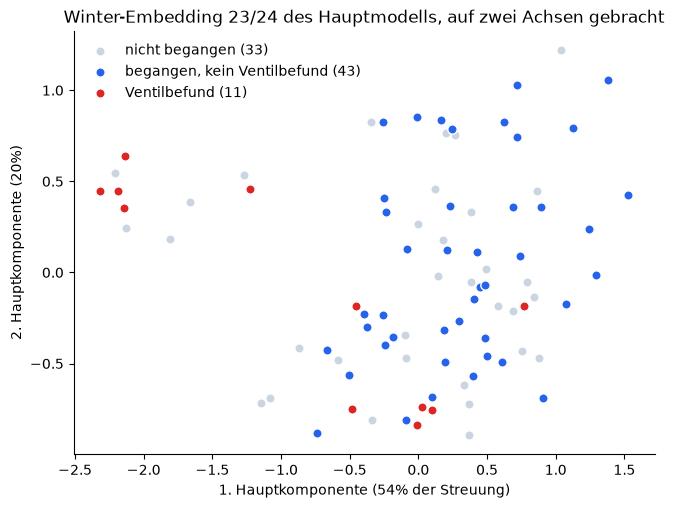

In [97]:
w = embedding.filter(like="lstm_w2324_").dropna()
pca = PCA(n_components=2).fit(w)
punkte = pd.DataFrame(pca.transform(w), index=w.index, columns=["pc1", "pc2"]).join(labels["ventil"])
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for wert, farbe, name in ((np.nan, "#CBD5E1", "nicht begangen"), (False, "#2563EB", "begangen, kein Ventilbefund"), (True, "#DC2626", "Ventilbefund")):
    teil = punkte[punkte["ventil"].isna()] if wert is np.nan else punkte[punkte["ventil"] == wert]
    ax.scatter(teil["pc1"], teil["pc2"], color=farbe, s=45, label=f"{name} ({len(teil)})", edgecolor="white")
ax.set_xlabel(f"1. Hauptkomponente ({pca.explained_variance_ratio_[0]:.0%} der Streuung)")
ax.set_ylabel(f"2. Hauptkomponente ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Winter-Embedding 23/24 des Hauptmodells, auf zwei Achsen gebracht")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Acht Zahlen kann man nicht zeichnen. Die Hauptkomponentenanalyse (PCA) sucht die zwei Richtungen, in denen die Stationen am stärksten streuen, und zeigt die Stationen darin. Gefärbt wird nach Ventilbefund, diese Farben hat das Netz nie gesehen.

Links, bei der 1. Hauptkomponente unter −1, sitzt eine eigene Gruppe mit 5 der 11 Ventilfälle, keiner begangenen Station ohne Befund und 7 nie begangenen Stationen (grau). Diese sieben sind erste Kandidaten, Notebook 29 rechnet das mit einem Modell nach. Die übrigen 6 Ventilfälle liegen in der Mitte zwischen den anderen, für sie reichen zwei Achsen nicht. Die beiden Achsen fassen 74 % der Streuung der acht Zahlen.

## 10 Fehlererkennung: Welche Station hatte bei der Begehung einen Befund?

Jetzt kommen die Labels dazu, mit dem Hauptmodell. Auf den Embeddings lernt eine logistische Regression, ob eine Station einen Ventil- oder Dämmungsbefund hatte. Geprüft wird verschachtelt: Außen wird jede Station einmal ausgelassen (Leave-one-out), innen wählt eine 4-fache Kreuzvalidierung nur auf den übrigen Stationen die Regularisierung `C`. Die ausgelassene Station beeinflusst also weder das Modell noch `C`.

Die AUC bekommt ein 95-%-Intervall aus 2000 Bootstrap-Ziehungen, bei denen die Stationen zufällig mit Zurücklegen neu gezogen werden. Dazu kommt Precision@10, also wie viele der zehn am höchsten eingestuften Stationen wirklich einen Befund hatten. Das beantwortet die Praxisfrage, welche zehn man zuerst begeht. Zur Vorgabe: Das Netz hat Tage der hier geprüften Stationen gesehen, aber nie ihre Labels und nie Tage nach ihrer Begehung. Die Labels kommen erst in der verschachtelt geprüften Regression vor.

In [98]:
KENNZAHLEN = [c for c in kz.columns if not c.startswith("stunden_") and c != "auslastung_vertrag"]
WINTER_KZ = [c for c in KENNZAHLEN if c.startswith("winter_") or c in ("auslastung", "anteil_volumenstrom", "streubreite_betriebspunkte", "ruecklauf_lastgewichtet")]

tabelle = labels[["ventil", "daemmung", "strasse_gruppe"]].join(kz).join(embedding)
basis = tabelle.dropna(subset=LSTM_WINTER + ["sommer_durchlauf_anteil"])
print(f"Prüfbasis: {len(basis)} begangene Zähler mit Winter-Embedding und Sommerwerten "
      f"(Ventil {int(basis['ventil'].sum())}, Dämmung {int(basis['daemmung'].sum())})")
print(f"Ausgeschlossen: {len(labels) - len(basis)} begangene Zähler ohne genug Winter- oder Sommertage")

VERFAHREN = {
    "Kennzahlen (alle)": KENNZAHLEN,
    "LSTM Winter + Sommer": LSTM_WINTER + LSTM_SOMMER,
    "Kennzahlen + LSTM": KENNZAHLEN + LSTM_WINTER + LSTM_SOMMER,
    "nur Winter: Kennzahlen": WINTER_KZ,
    "nur Winter: LSTM": LSTM_WINTER,
    "nur Winter: Kennzahlen + LSTM": WINTER_KZ + LSTM_WINTER,
}
scores = {}
for ziel in ("ventil", "daemmung"):
    y = basis[ziel].astype(int).to_numpy()
    scores[(ziel, "Sommernacht-Regel (ohne Lernen)")] = basis["sommer_durchlauf_anteil"].to_numpy()
    for name, spalten in VERFAHREN.items():
        scores[(ziel, name)] = verschachtelt(basis[spalten], y)

zeilen = []
for (ziel, name), s in scores.items():
    y = basis[ziel].astype(int).to_numpy()
    auc, unten, oben = auc_mit_intervall(y, s)
    zeilen.append({"Ziel": ziel, "Verfahren": name, "AUC": auc, "unten": unten, "oben": oben, "P@10": precision_at_k(y, s)})
ergebnis = pd.DataFrame(zeilen)
ergebnis.round(2)

Prüfbasis: 53 begangene Zähler mit Winter-Embedding und Sommerwerten (Ventil 11, Dämmung 22)
Ausgeschlossen: 3 begangene Zähler ohne genug Winter- oder Sommertage


,Ziel,Verfahren,AUC,unten,oben,P@10
0,ventil,Sommernacht-Regel (ohne Lernen),0.85,0.68,0.98,0.7
1,ventil,Kennzahlen (alle),0.79,0.57,0.97,0.6
2,ventil,LSTM Winter + Sommer,0.84,0.70,0.94,0.5
3,ventil,Kennzahlen + LSTM,0.89,0.78,0.97,0.7
4,ventil,nur Winter: Kennzahlen,0.68,0.44,0.89,0.5
5,ventil,nur Winter: LSTM,0.83,0.68,0.95,0.5
6,ventil,nur Winter: Kennzahlen + LSTM,0.79,0.61,0.94,0.6
7,daemmung,Sommernacht-Regel (ohne Lernen),0.57,0.40,0.73,0.6
8,daemmung,Kennzahlen (alle),0.69,0.53,0.84,0.9
9,daemmung,LSTM Winter + Sommer,0.72,0.57,0.85,0.7


Verglichen werden mehrere Merkmalsgruppen: die Kennzahlen aus Notebook 25, die LSTM-Embeddings aus Winter und Sommer, beides zusammen und drei Varianten nur mit Winterdaten. Die Prüfbasis ist für alle Verfahren gleich, 53 begangene Zähler mit Winter-Embedding und Sommerwerten (Ventil 11, Dämmung 22), sonst wären die AUC-Werte nicht vergleichbar. Messlatte ohne Lernen ist die Sommernacht-Regel, die die Stationen nach dem Anteil der Sommernächte mit Durchfluss sortiert. `auslastung_vertrag` bleibt draußen, weil sie nur für begangene Zähler bekannt ist und zur Überdimensionierung gehört (Notebook 29).

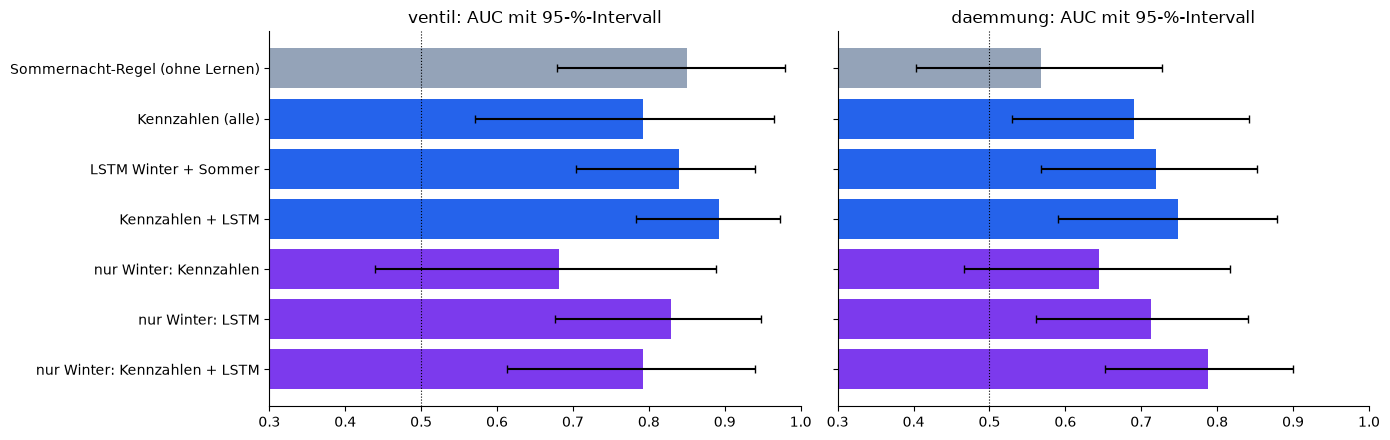

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
for ax, ziel in zip(axes, ("ventil", "daemmung")):
    t = ergebnis[ergebnis["Ziel"] == ziel].reset_index(drop=True)
    farben = ["#94A3B8" if "Regel" in v else "#7C3AED" if v.startswith("nur Winter") else "#2563EB" for v in t["Verfahren"]]
    ax.barh(t["Verfahren"], t["AUC"], xerr=[t["AUC"] - t["unten"], t["oben"] - t["AUC"]], color=farben, capsize=3)
    ax.axvline(0.5, color="black", lw=0.8, ls=":")
    ax.set_xlim(0.3, 1.0)
    ax.invert_yaxis()
    ax.set_title(f"{ziel}: AUC mit 95-%-Intervall")
    ax.spines[["top", "right"]].set_visible(False)
axes[1].set_yticklabels([])
fig.tight_layout()
plt.show()

Die Grafik zeigt die AUC je Verfahren mit Bootstrap-Intervall. Grau ist die Regel ohne Lernen, blau sind Verfahren mit Sommerdaten, violett solche nur mit Winterdaten. Die gepunktete Linie ist Raten.

Beim Hauptmodell, das nur auf begangenen HAST gelernt hat, sieht es so aus. Beim Ventil (11 von 53, Basisrate 21 %) erreicht mit Sommerdaten die Regel ohne Lernen 0,85, Kennzahlen und LSTM zusammen kommen auf 0,89 [0,78; 0,97]. Nur mit Winterdaten erreichen die Kennzahlen 0,68, das LSTM 0,83 und beides zusammen 0,79. Das LSTM liegt vorne, aber mit breitem Intervall (0,68 bis 0,95).

Bei der Dämmung (22 von 53, Basisrate 42 %) sagt die Sommernacht-Regel nichts (0,57), was passt, denn sie misst das Ventil. Mit Lernen kommen die Kennzahlen auf 0,69, das LSTM auf 0,72 und beides auf 0,75, nur mit dem Winter beides zusammen auf 0,79. Unter den zehn höchsten Stationen haben mit Kennzahlen 9 einen Dämmungsbefund, Zufall wären 4.

### 10.1 Ist der Unterschied belegt?

Zwei AUC-Werte mit überlappenden Intervallen können trotzdem verschieden sein, weil beide auf denselben Stationen gemessen werden. Richtig ist deshalb der gepaarte Vergleich. In jeder Bootstrap-Ziehung werden beide Verfahren auf derselben Stichprobe bewertet, und die Differenz wird gemerkt. Schließt das 95-%-Intervall der Differenz die 0 aus, gilt der Unterschied als belegt.

In [100]:
def auc_differenz(y, a, b, n=2000):
    rng = np.random.default_rng(SEED)
    differenzen = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            differenzen.append(roc_auc_score(y[i], a[i]) - roc_auc_score(y[i], b[i]))
    return roc_auc_score(y, a) - roc_auc_score(y, b), np.quantile(differenzen, 0.025), np.quantile(differenzen, 0.975)


VERGLEICHE = [
    ("ventil", "nur Winter: LSTM", "nur Winter: Kennzahlen"),
    ("ventil", "nur Winter: LSTM", "Sommernacht-Regel (ohne Lernen)"),
    ("ventil", "Kennzahlen + LSTM", "Sommernacht-Regel (ohne Lernen)"),
    ("ventil", "Kennzahlen + LSTM", "Kennzahlen (alle)"),
    ("daemmung", "Kennzahlen + LSTM", "Kennzahlen (alle)"),
    ("daemmung", "nur Winter: LSTM", "nur Winter: Kennzahlen"),
]
zeilen = []
for ziel, a, b in VERGLEICHE:
    y = basis[ziel].astype(int).to_numpy()
    d, unten, oben = auc_differenz(y, scores[(ziel, a)], scores[(ziel, b)])
    zeilen.append({"Ziel": ziel, "Verfahren": a, "gegen": b, "Differenz": d, "unten": unten, "oben": oben,
                   "belegt": "ja" if unten > 0 or oben < 0 else "nein"})
pd.DataFrame(zeilen).round(2)

,Ziel,Verfahren,gegen,Differenz,unten,oben,belegt
0,ventil,nur Winter: LSTM,nur Winter: Kennzahlen,0.15,0.02,0.32,ja
1,ventil,nur Winter: LSTM,Sommernacht-Regel (ohne Lernen),-0.02,-0.15,0.13,nein
2,ventil,Kennzahlen + LSTM,Sommernacht-Regel (ohne Lernen),0.04,-0.04,0.15,nein
3,ventil,Kennzahlen + LSTM,Kennzahlen (alle),0.10,-0.02,0.25,nein
4,daemmung,Kennzahlen + LSTM,Kennzahlen (alle),0.06,-0.07,0.21,nein
5,daemmung,nur Winter: LSTM,nur Winter: Kennzahlen,0.07,-0.10,0.23,nein


`auc_differenz()` zieht 2000-mal eine Stichprobe der Stationen und berechnet in jeder Ziehung die AUC beider Verfahren auf denselben Stationen. Die Tabelle zeigt die Differenz, ihr 95-%-Intervall und ob die 0 ausgeschlossen ist.

Belegt ist ein Unterschied: Beim Ventil im Winter liegt das LSTM vor den Kennzahlen (+0,15, Intervall +0,02 bis +0,32). Alle anderen Unterschiede sind nicht belegt. Die Richtung ist aber überall dieselbe, das LSTM liegt vor den Kennzahlen, beim Ventil mit allen Daten um +0,10 und bei der Dämmung um +0,06 bis +0,07. Gegen die Sommernacht-Regel ist das LSTM mit Sommerdaten gleichauf (+0,04). Wer den Sommer abwarten kann, kommt mit der einfachen Regel aus. Der Wintervorsprung ist empfindlich. Bei 11 Fällen hängt seine untere Grenze schon am Zufall des Trainings, woran vor allem, zeigt Abschnitt 10.2.

In [101]:
#Von Hand nachgerechnet: die AUC ist der Anteil der Paare (Befund, kein Befund),
#in denen die Station mit Befund den höheren Score hat (Gleichstand zählt halb).
y = basis["ventil"].astype(int).to_numpy()
s = scores[("ventil", "nur Winter: LSTM")]
pos, neg = s[y == 1], s[y == 0]
paare = (pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean()
print(f"{len(pos)} × {len(neg)} = {len(pos) * len(neg)} Paare, davon richtig herum: {paare:.3f}")
assert np.isclose(paare, roc_auc_score(y, s))
print("stimmt mit roc_auc_score überein")

#Und noch einmal mit ganzen Straßen statt einzelnen Stationen ausgelassen
gruppen = basis["strasse_gruppe"].to_numpy()
for ziel, name in (("ventil", "nur Winter: LSTM"), ("ventil", "Kennzahlen + LSTM"), ("daemmung", "Kennzahlen + LSTM")):
    yz = basis[ziel].astype(int).to_numpy()
    auc, unten, oben = auc_mit_intervall(yz, verschachtelt(basis[VERFAHREN[name]], yz, gruppen))
    print(f"Straßen ausgelassen – {ziel:8s} {name:28s} AUC {auc:.2f} [{unten:.2f}; {oben:.2f}]")

11 × 42 = 462 Paare, davon richtig herum: 0.829
stimmt mit roc_auc_score überein


Straßen ausgelassen – ventil   nur Winter: LSTM             AUC 0.87 [0.74; 0.97]


Straßen ausgelassen – ventil   Kennzahlen + LSTM            AUC 0.83 [0.66; 0.94]


Straßen ausgelassen – daemmung Kennzahlen + LSTM            AUC 0.82 [0.69; 0.92]


Die Zelle rechnet eine AUC ohne scikit-learn nach. Über alle Paare aus einer Station mit und einer ohne Befund wird gezählt, wie oft die mit Befund vorne liegt. Danach wiederholt sie drei Prüfungen, bei denen immer eine ganze Straße ausgelassen wird, denn begangen wurde Straße für Straße, und Nachbarhäuser ähneln sich. Bleibt die AUC ähnlich hoch, hat das Modell nicht nur Nachbarn wiedererkannt.

Die AUC von Hand über 462 Paare stimmt mit `roc_auc_score` überein (0,829). Ganze Straßen auszulassen ändert wenig, das Ventil im Winter kommt auf 0,87, das Ventil mit allen Daten auf 0,83 und die Dämmung auf 0,82. Das Modell erkennt also nicht nur Nachbarhäuser wieder, deren Straße schon im Training war.

### 10.2 Ein fragliches Label: Wie viel hängt daran?

Die Freitextkodierung (`src/befundcodes.py`) zählt bei einem Zähler „Regelventil geölt und Funktion überprüft“ als Ventilbefund. Das beschreibt eher Wartung als einen Defekt, und die Station zeigt im Sommer kein Ventilbild. Ob das Label bleibt, entscheidet das Team. Hier wird nur gezeigt, wie viel daran hängt, mit derselben Prüfung einmal mit und einmal ohne diesen Zähler. Das Label selbst wird nicht verändert.

In [102]:
FRAGLICH = 80912189
ohne = basis.drop(index=FRAGLICH, errors="ignore")
zeilen = []
for name in ("nur Winter: LSTM", "Kennzahlen + LSTM", "nur Winter: Kennzahlen"):
    for daten, fassung in ((basis, "mit dem Zähler (Team-Label)"), (ohne, "ohne den Zähler")):
        y = daten["ventil"].astype(int).to_numpy()
        auc, unten, oben = auc_mit_intervall(y, verschachtelt(daten[VERFAHREN[name]], y))
        zeilen.append({"Verfahren": name, "Fassung": fassung, "Stationen": len(daten), "Ventilfälle": int(y.sum()),
                       "AUC": auc, "unten": unten, "oben": oben})
print(f"Zähler {FRAGLICH}: Ventil-Label = {bool(labels.loc[FRAGLICH, 'ventil'])}, "
      f"Sommer-Durchlaufanteil {kz.loc[FRAGLICH, 'sommer_durchlauf_anteil']:.2f}, Nachtdurchfluss {kz.loc[FRAGLICH, 'sommer_nachtfluss_lph']:.0f} l/h")
fassungen = pd.DataFrame(zeilen)

#Der gepaarte Vergleich aus Abschnitt 6, jetzt auch ohne den fraglichen Zähler
y = ohne["ventil"].astype(int).to_numpy()
d, unten, oben = auc_differenz(y, verschachtelt(ohne[VERFAHREN["nur Winter: LSTM"]], y),
                               verschachtelt(ohne[VERFAHREN["nur Winter: Kennzahlen"]], y))
print(f"ohne den Zähler: nur Winter LSTM gegen nur Winter Kennzahlen: {d:+.2f} [{unten:+.2f}; {oben:+.2f}] "
      f"-> {'belegt' if unten > 0 else 'nicht belegt'}")
fassungen.round(2)

Zähler 80912189: Ventil-Label = True, Sommer-Durchlaufanteil 0.13, Nachtdurchfluss 0 l/h


ohne den Zähler: nur Winter LSTM gegen nur Winter Kennzahlen: +0.12 [+0.00; +0.26] -> belegt


,Verfahren,Fassung,Stationen,Ventilfälle,AUC,unten,oben
0,nur Winter: LSTM,mit dem Zähler (Team-Label),53,11,0.83,0.68,0.95
1,nur Winter: LSTM,ohne den Zähler,52,10,0.89,0.78,0.98
2,Kennzahlen + LSTM,mit dem Zähler (Team-Label),53,11,0.89,0.78,0.97
3,Kennzahlen + LSTM,ohne den Zähler,52,10,0.88,0.70,0.99
4,nur Winter: Kennzahlen,mit dem Zähler (Team-Label),53,11,0.68,0.44,0.89
5,nur Winter: Kennzahlen,ohne den Zähler,52,10,0.78,0.58,0.94


Die Zelle rechnet drei Ventil-Prüfungen zweimal, mit und ohne den fraglichen Zähler 80912189. Daneben steht, wie die Station im Sommer aussah, denn ein undichtes Ventil lässt nachts Wasser durch.

An diesem einen Zähler hängt der Winterwert. Das LSTM kommt im Winter mit ihm auf 0,83, ohne ihn auf 0,89 [0,78; 0,98]. Kennzahlen und LSTM zusammen bleiben bei 0,89 bzw. 0,88, die Winter-Kennzahlen steigen von 0,68 auf 0,78. Der Zähler zeigt kein Ventilbild, im Sommer lief nachts in 13 % der Stunden Wasser, im Median 0 l/h, während es bei echten Ventilfällen meist über 90 % sind. Ohne ihn ist der Wintervorsprung des LSTM vor den Kennzahlen gerade eben belegt (+0,12, untere Grenze knapp über 0). Das Label bleibt unverändert, die Tabelle zeigt nur, wie viel von der Entscheidung des Teams abhängt.

## 11 Ergebnis speichern

Die Zelle speichert Embeddings und Prüf-Vorhersagen nach `data/processed/`.

In [103]:
embedding.to_csv(PROCESSED / "lstm_embedding.csv")
oof = pd.DataFrame({f"{ziel} | {name}": s for (ziel, name), s in scores.items()}, index=basis.index)
oof.to_csv(PROCESSED / "lstm_scores.csv")
print(f"lstm_embedding.csv: {embedding.shape},  lstm_scores.csv: {oof.shape}")

lstm_embedding.csv: (90, 24),  lstm_scores.csv: (53, 14)


`lstm_embedding.csv` enthält die Embeddings des Hauptmodells für alle 90 Zähler, auch die nicht begangenen. Notebook 29 nutzt sie als Merkmale neben den Kennzahlen. `lstm_scores.csv` enthält die Vorhersagen aus der Prüfung für 53 Zähler, damit sie sich später ohne neues Lernen vergleichen lassen.

## Zusammenfassung & Bewertung

**Ergebnis**

Die Vorversuche zeigen, dass ein LSTM mit Early Stopping von selbst stoppt, bevor es auswendig lernt. Der beste Stand liegt in Runde 39, ohne Bremse steigt der Validierungsfehler danach wieder. Ein Engpass von 8 Zahlen kostet bei der Vorhersage nur gut 1 %, und der Steckbrief aus 8 Zahlen erkennt 19 von 23 Stationen im nächsten Winter wieder, 3 Mittelwerte nur 13.

Das endgültige LSTM hat 116.941 Gewichte und lernt auf der GPU in 11 Sekunden. Es sagt aus einem Tag einer Station den nächsten vorher und beschreibt dabei jeden Tag in acht Zahlen, je Station ergeben Winter und Sommer 16 Zahlen. Nach Vorgabe der Betreuung lernt es nur aus begangenen HAST, nur aus Tagen vor der Begehung und ohne ein Label. Angewendet wird es auf alle 90 Zähler mit vollständigen Tagen (`lstm_embedding.csv`).

Beim Ventil kommen Kennzahlen und LSTM zusammen mit allen Daten auf eine AUC von 0,89 [0,78; 0,97], bei der Dämmung auf 0,72 bis 0,79 mit einer Precision@10 bis 0,9. Diese Zahlen sind ein erster Stand, die strengere Prüfung in Notebook 35 kommt mit Modellwahl im Lernteil auf Ventil 0,84 und Dämmung 0,78. Im Winter liegt das LSTM beim Ventil vor den Kennzahlen, 0,83 gegen 0,68 (+0,15 [0,02; 0,32]), ohne den fraglichen Fall 0,89 gegen 0,78.

**Belastbar**

Ohne Labels werden über zwei Winter 83 % der Stationen wiedererkannt, bei nie gesehenen Stationen 78 % (Zufall 2 %). Das Netz beschreibt also auch Stationen, die es nie gesehen hat, und das ist die Grundlage, nie begangene HAST einzustufen (Notebook 29). Ventil und Dämmung liegen deutlich über Raten und halten, wenn ganze Straßen ausgelassen werden (AUC 0,82 bis 0,87). Die Vorgabe „nur begangene HAST“ kostet nichts Messbares, und der Autoencoder erkennt Stationen deutlich schlechter wieder (0,73), was die Aufgabe „Vorhersagen“ bestätigt. Ein Lauf ohne gespeicherte Gewichte liefert dieselben Zahlen.

**Schwach**

Mit allen Daten ist das LSTM beim Ventil nicht belegt besser als die einfache Sommernacht-Regel (0,85). Der Wintervorsprung beim Ventil ist in diesem Lauf knapp belegt, aber nicht stabil, denn bei 11 Fällen hängt er am Zufall des Trainings, und ein einziges Label verschiebt die Winter-AUC um 0,06. Die übrigen Vorsprünge des LSTM vor den Kennzahlen (+0,06 bis +0,10) sind nicht abgesichert. Die Größe des Engpasses weicht von der vorher festgelegten Regel ab (8 statt 16), begründet in Abschnitt 5.4, der Unterschied liegt im Rauschen.

**Offen**

Ob „Regelventil geölt und Funktion überprüft“ ein Ventilbefund bleibt, entscheidet das Team. Ob die Embeddings für alle Fehlerarten helfen, prüft Notebook 29 mit XGBoost. Notebook 28 nutzt dieselbe Idee als Wächter: Ein LSTM sagt den nächsten Tag vorher und warnt, wenn die Station davon abweicht.